# RL training for LLM agents — 1. GRPO from scratch


# Motivation

The latest frontier of LLM innovation seems to be driven by reinforcement learning training; with large labs spending an increasing amount of their compute on post-training RL. This is especially prevalent in 'reasoning' domains, where it is possible to verify an outcome rather than relying on a correct label, such as Maths and coding.

Frameworks like [verl](https://github.com/volcengine/verl) make it possible to train LLMs with reinforcement learning (RL) across many GPUs, but they are also large, layered codebases: Ray workers, FSDP, an inference engine with weight sync, agent loops, a few hundred config options. When something goes wrong, or when we want to train an agent that doesn't fit the framework's mould, it is hard to know which of those layers matters, and why it exists at all.

Jeremy Howard's [*What is `torch.nn` really?*](https://pytorch.org/tutorials/beginner/nn_tutorial.html) has a great answer to this kind of problem: train a model with nothing but tensors, then replace one hand-written piece at a time with its library equivalent, until only idiomatic library code is left. After every swap the code still runs, and we know exactly what each library piece does, because we wrote it first. This inspired me to take a similar approch for RL training of LLMs.

As a first step, I wanted to really dive deep into the algorithmic side of the process, in an attempt to answer some of the questions I had:

1. What does it mean to train an LLM with RL? (§1.1–§1.2)
2. How likely is a given response under the model, and how do we compute it? (§1.3)
3. How do we make a good response more likely when the reward has no gradient? (§1.4)
4. What does the training loop look like

By the end we have a complete GRPO trainer in plain PyTorch, checked against verl's. [Notebook 2](2_from_trainer_to_verl.ipynb) picks up from there: it hands generation to a real inference engine (vLLM), then turns the trainer into a distributed system, one swap at a time, until it *is* verl.

## 0. Setup

In [1]:
import random
import sys
import time
from pathlib import Path

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "examples" / "calc_x").is_dir())
sys.path.insert(0, str(REPO / "tutorial/lib"))  # the series' shared code: paths, the model name, the seed
from common import DEVICE, MODEL, SEED, SHM, gpu_free_gib, setup  # noqa: E402

setup()  # creates the working folders, seeds the random number generators, checks the GPU is free

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import torch  # noqa: E402

repo: /home/azureuser/localfiles/agl-rl-tutorials
python: /home/azureuser/localfiles/agl-rl-tutorials/.venv/bin/python
GPU: NVIDIA H100 NVL, 93 of 93 GiB free


## 1. GRPO by hand

### 1.1 Task

Improve policy at maths problems


First, lets make some questions

In [2]:
import random
import ast
import operator

_BINARY_OPS = {ast.Add: operator.add, ast.Sub: operator.sub, ast.Mult: operator.mul, ast.Div: operator.truediv}
_UNARY_OPS = {ast.USub: operator.neg, ast.UAdd: operator.pos}



def make_problems(num_problems: int, seed: int, hard: bool = False) -> list[dict]:
    rng = random.Random(seed)
    problems = []
    for _ in range(num_problems):
        if hard:  # e.g. "482 * 917 - 3051": too big to multiply reliably without a calculator
            expression = " ".join([str(rng.randint(100, 999)), "*", str(rng.randint(100, 999)), "-", str(rng.randint(1000, 9999))])
        else:     # e.g. "37 + 12 * 5"
            expression = " ".join([
                str(rng.randint(2, 99)), rng.choice("+-*"),
                str(rng.randint(2, 99)), rng.choice("+-*"),
                str(rng.randint(2, 30)),
            ])
        problems.append({"question": f"What is {expression}?", "answer": int(safe_eval(expression))})
    return problems


def safe_eval(expression: str) -> float:
    """Evaluate `+ - * /` arithmetic by walking the syntax tree; anything else is rejected."""
    if len(expression) > 200:
        raise ValueError("expression too long")

    def evaluate_node(node):
        if isinstance(node, ast.Expression):  # the root of the tree
            return evaluate_node(node.body)
        if isinstance(node, ast.Constant) and type(node.value) in (int, float):  # a number
            return node.value
        if isinstance(node, ast.BinOp) and type(node.op) in _BINARY_OPS:  # e.g. 2 + 3
            apply_op = _BINARY_OPS[type(node.op)]
            return apply_op(evaluate_node(node.left), evaluate_node(node.right))
        if isinstance(node, ast.UnaryOp) and type(node.op) in _UNARY_OPS:  # e.g. -5
            apply_op = _UNARY_OPS[type(node.op)]
            return apply_op(evaluate_node(node.operand))
        raise ValueError(f"unsupported expression: {expression!r}")  # names, calls, **, ...

    return evaluate_node(ast.parse(expression, mode="eval"))




In [3]:
problems = make_problems(6, seed=1)
for problem in problems:
    print(problem)

{'question': 'What is 19 * 99 + 10?', 'answer': 1891}
{'question': 'What is 17 - 99 - 17?', 'answer': -99}
{'question': 'What is 85 - 28 + 17?', 'answer': 74}
{'question': 'What is 5 - 57 * 26?', 'answer': -1477}
{'question': 'What is 2 * 59 - 25?', 'answer': 93}
{'question': 'What is 31 * 15 - 2?', 'answer': 463}


In [4]:
TRAIN = make_problems(4000, seed=1)
EVAL = make_problems(200, seed=2)


In [5]:
TRAIN[:5], EVAL[:5]

([{'question': 'What is 19 * 99 + 10?', 'answer': 1891},
  {'question': 'What is 17 - 99 - 17?', 'answer': -99},
  {'question': 'What is 85 - 28 + 17?', 'answer': 74},
  {'question': 'What is 5 - 57 * 26?', 'answer': -1477},
  {'question': 'What is 2 * 59 - 25?', 'answer': 93}],
 [{'question': 'What is 9 + 12 - 28?', 'answer': -7},
  {'question': 'What is 23 * 87 - 10?', 'answer': 1991},
  {'question': 'What is 79 + 79 + 20?', 'answer': 178},
  {'question': 'What is 89 + 57 * 14?', 'answer': 887},
  {'question': 'What is 94 * 49 * 16?', 'answer': 73696}])

We need a reward function

In [6]:
import re

BOXED = re.compile(r"\\boxed\{\s*(-?\d[\d,]*)\s*\}")


def reward_fn(text: str, answer: int) -> float:
    """1.0 if the last \\boxed{...} in `text` holds `answer`, else 0.0."""
    boxed_numbers = BOXED.findall(text)  # e.g. ["12", "1,234"]
    if not boxed_numbers:
        return 0.0
    final_answer = int(boxed_numbers[-1].replace(",", ""))
    return 1.0 if final_answer == answer else 0.0

In [7]:
for text, answer in [
    (r"... so \boxed{42}",  42),   # correct answer, correct format
    (r"\boxed{41}",         42),   # wrong answer
    ("The answer is 42.",   42),   # right answer, wrong format!
    (r"\boxed{1,234}",    1234),   # commas are fine
]:
    print(f"  reward = {reward_fn(text, answer)}  ←  {text!r}")

  reward = 1.0  ←  '... so \\boxed{42}'
  reward = 0.0  ←  '\\boxed{41}'
  reward = 0.0  ←  'The answer is 42.'
  reward = 1.0  ←  '\\boxed{1,234}'


### 1.2 Sampling from the policy

In [8]:
from transformers import AutoModelForCausalLM, AutoTokenizer, GenerationConfig
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()
tokenizer = AutoTokenizer.from_pretrained(MODEL)


def load_policy(path: str = MODEL):
    model = AutoModelForCausalLM.from_pretrained(path, dtype=torch.float32, attn_implementation="flash_attention_2")  # fp32 master weights
    model = model.to(DEVICE)
    model.config.use_cache = False  # the KV cache only speeds up generation, not training
    return model

/home/azureuser/localfiles/agl-rl-tutorials/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [9]:
policy = load_policy()
print(f"policy: {sum(param.numel() for param in policy.parameters()) / 1e6:.0f}M parameters")

PAD_ID = tokenizer.pad_token_id
STOP_IDS = {tokenizer.convert_tokens_to_ids("<|im_end|>"), tokenizer.convert_tokens_to_ids("<|endoftext|>")}

policy: 494M parameters


In [10]:
INSTRUCTION = r"Show brief working, then give the final answer as \boxed{N}."

def chat_prompt_ids(question: str) -> list[int]:
    """The question plus our instruction, wrapped in the model's chat template, as token IDs."""
    messages = [{"role": "user", "content": f"{question} {INSTRUCTION}"}]
    return tokenizer.apply_chat_template(messages, add_generation_prompt=True)


def decode_tokens(ids) -> str:
    return tokenizer.decode(ids, skip_special_tokens=True)

In [11]:
encoded = chat_prompt_ids(TRAIN[0])
print(encoded[:5])
print('-----')
print(decode_tokens(encoded))

[151644, 8948, 198, 2610, 525]
-----
system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.
user
{'question': 'What is 19 * 99 + 10?', 'answer': 1891} Show brief working, then give the final answer as \boxed{N}.
assistant



In [12]:
TRAIN[0]

{'question': 'What is 19 * 99 + 10?', 'answer': 1891}

In [13]:
def hf_generate_single(model, prompt_tokens, max_new_tokens = 256):
    with torch.no_grad():

        input_ids = torch.as_tensor(prompt_tokens)[None]
        attention_mask = torch.ones_like(input_ids)

        model.eval()

        with torch.autocast("cuda", dtype=torch.bfloat16):
            output_ids = model.generate(
                        input_ids=input_ids.to(DEVICE), attention_mask=attention_mask.to(DEVICE),
                        do_sample=True, temperature=1.0, top_p=1.0, top_k=0, repetition_penalty=1.0,
                        max_new_tokens=max_new_tokens, pad_token_id=PAD_ID, use_cache=True,
                    )
        
        model.train()

        return output_ids



In [14]:
input_prompt = chat_prompt_ids(TRAIN[0]['question'])

output_ids = hf_generate_single(policy, input_prompt)

In [15]:
output_ids.tolist()[0][:5]

[151644, 8948, 198, 2610, 525]

In [16]:
from pprint import pprint

In [17]:
full_response_text = decode_tokens(output_ids.tolist()[0])
pprint(full_response_text)

('system\n'
 'You are Qwen, created by Alibaba Cloud. You are a helpful assistant.\n'
 'user\n'
 'What is 19 * 99 + 10? Show brief working, then give the final answer as '
 '\\boxed{N}.\n'
 'assistant\n'
 'To solve the expression \\(19 \\times 99 + 10\\), we will follow these '
 'steps:\n'
 '\n'
 '1. Calculate \\(19 \\times 99\\).\n'
 '2. Add 10 to the result from step 1.\n'
 '\n'
 "Let's go through each step in detail:\n"
 '\n'
 '### Step 1: Calculate \\(19 \\times 99\\)\n'
 '\n'
 'To perform this multiplication, we can break it down:\n'
 '\\[19 \\times 99 = 19 \\times (100 - 1) = 19 \\times 100 - 19 \\times 1.\\]\n'
 '\n'
 'Now, calculate each part separately:\n'
 '\\[19 \\times 100 = 1900,\\]\n'
 '\\[19 \\times 1 = 19.\\]\n'
 '\n'
 'Subtract the second product from the first:\n'
 '\\[1900 - 19 = 1881.\\]\n'
 '\n'
 'So, \\(19 \\times 99 = 1881\\).\n'
 '\n'
 '### Step 2: Add 10 to the result from step 1\n'
 '\n'
 'Now we need to add 10 to 1881:\n'
 '\\[1881 + 10 = 189')


In [18]:
response_text = decode_tokens(output_ids.tolist()[0][len(input_prompt):])
pprint(response_text)


('To solve the expression \\(19 \\times 99 + 10\\), we will follow these '
 'steps:\n'
 '\n'
 '1. Calculate \\(19 \\times 99\\).\n'
 '2. Add 10 to the result from step 1.\n'
 '\n'
 "Let's go through each step in detail:\n"
 '\n'
 '### Step 1: Calculate \\(19 \\times 99\\)\n'
 '\n'
 'To perform this multiplication, we can break it down:\n'
 '\\[19 \\times 99 = 19 \\times (100 - 1) = 19 \\times 100 - 19 \\times 1.\\]\n'
 '\n'
 'Now, calculate each part separately:\n'
 '\\[19 \\times 100 = 1900,\\]\n'
 '\\[19 \\times 1 = 19.\\]\n'
 '\n'
 'Subtract the second product from the first:\n'
 '\\[1900 - 19 = 1881.\\]\n'
 '\n'
 'So, \\(19 \\times 99 = 1881\\).\n'
 '\n'
 '### Step 2: Add 10 to the result from step 1\n'
 '\n'
 'Now we need to add 10 to 1881:\n'
 '\\[1881 + 10 = 189')


In [19]:
reward = reward_fn(response_text, TRAIN[0]["answer"]); reward

0.0

However, language models are non-deterministic. Lets sample multiple responses for the same question and observe what happens.

In [20]:
from tqdm import tqdm
num_trials = 10
samples = []
torch.manual_seed(SEED)  # the same samples every time this cell runs

for _ in tqdm(range(num_trials)):
    input_prompt = chat_prompt_ids(TRAIN[0]["question"])
    
    output_ids = hf_generate_single(policy, input_prompt)
    
    response_ids = output_ids[0, len(input_prompt):].tolist()
    response_text = decode_tokens(response_ids)
    
    samples.append({
        "prompt_ids": input_prompt,
        "response_ids": response_ids,
        "text": response_text,
        "reward": reward_fn(response_text, TRAIN[0]["answer"]),
    })

rewards = [sample["reward"] for sample in samples]
print(f"rewards: {rewards}  ({sum(rewards):.0f}/{num_trials} correct)")


  0%|          | 0/10 [00:00<?, ?it/s]

100%|██████████| 10/10 [00:37<00:00,  3.79s/it]

rewards: [0.0, 0.0, 1.0, 1.0, 1.0, 1.0, 0.0, 0.0, 1.0, 1.0]  (6/10 correct)


### 1.3 How likely is a response?

Some of the samples above are correct and some aren't. **The goal of training is to make the model produce the correct ones more often.**

We can't differentiate the reward. It comes from checking the text with a regex, and the text comes from random sampling, so there's no gradient from "the answer was right" back to the model's weights. What the weights *do* control is how likely each response is: the model's output probabilities are a smooth function of its weights. **Policy-gradient methods use that:** instead of differentiating the reward, they push up the probability of responses the reward liked. The reward never needs a gradient; it only decides which responses to push, and how hard. That's why it can be anything we can compute: a regex, a unit test, another model's verdict.

So we turn "produce correct answers more often" into "**make the correct responses we've seen more likely**". For that we need a number for how likely a response is under the model *now*, and a way to push it up. (This is the same number supervised fine-tuning maximises for its target text. In RL, the text is the model's own samples, and the reward decides which ones to push up.)

The model writes a response one token at a time.

 At each step it outputs a probability distribution over every possible next token in the vocab, conditioned on everything so far (the prompt plus the response up to that point). 
 
The probability of a whole response is the probability of making each of those choices, one after another:

$$\pi(\text{response}) = p(\text{token}_1) \times p(\text{token}_2 \mid \text{token}_1) \times p(\text{token}_3 \mid \text{token}_1, \text{token}_2) \times \dots$$

We write it as π (the *policy*): the model viewed as a rule for choosing actions, where each action is a token.

In practice we never multiply these probabilities. We add their logs:

$$\log \pi(\text{response}) = \log p(\text{token}_1) + \log p(\text{token}_2 \mid \text{token}_1) + \dots$$

It's the same information in a more convenient form. Take a 200-token response where the model gave every token p = 0.9. The product is 0.9²⁰⁰ ≈ 7×10⁻¹⁰, a number too small to read or compare at a glance. The sum of logs is 200 × log 0.9 ≈ −21, an ordinary number. Longer responses make it worse: at 1,000 tokens the product is about 10⁻⁴⁶, which is below the smallest number a float32 can store, so it becomes exactly 0. The sum is just −105. The sum also splits into one term per token, which will matter when we train.

#### Getting the token probabilities from the model

In addition to using these probabilities to sample the next token from the distribution, we can also use it to score how likely the model thought a given token should be next in the sequence. This can be extended to sequences of tokens.

One forward pass over **prompt + response** does it. At every position, the model outputs a score (a *logit*) for each of the ~152,000 tokens in its vocabulary. That's its guess for what comes **next**. `log_softmax` turns those scores into log-probabilities.




In [21]:
len(samples)
samples[0].keys()

dict_keys(['prompt_ids', 'response_ids', 'text', 'reward'])

In [22]:
samples[0]['text'], samples[0]['reward']

("To solve the expression \\(19 \\times 99 + 10\\), we will follow these steps:\n\n1. Calculate \\(19 \\times 99\\).\n2. Add 10 to the result from step 1.\n\nLet's go through each step in detail:\n\n### Step 1: Calculate \\(19 \\times 99\\)\n\nTo perform this multiplication, we can break it down:\n\\[19 \\times 99 = 19 \\times (100 - 1) = 19 \\times 100 - 19 \\times 1.\\]\n\nNow, calculate each part separately:\n\\[19 \\times 100 = 1900,\\]\n\\[19 \\times 1 = 19.\\]\n\nSubtract the second product from the first:\n\\[1900 - 19 = 1881.\\]\n\nSo, \\(19 \\times 99 = 1881\\).\n\n### Step 2: Add 10 to the result from step 1\n\nNow we need to add 10 to 1881:\n\\[1881 + 10 = 189",
 0.0)

In [23]:
prompt_ids = samples[0]['prompt_ids']
response_ids = samples[0]["response_ids"]

with torch.autocast("cuda", dtype=torch.bfloat16):
    input_ids = torch.tensor([prompt_ids + response_ids], device=DEVICE)
    logits = policy(input_ids=input_ids).logits

In [24]:
input_ids.shape, logits.shape

(torch.Size([1, 314]), torch.Size([1, 314, 151936]))

In [25]:
log_probs_over_vocab = torch.log_softmax(logits, dim=-1); log_probs_over_vocab.shape


torch.Size([1, 314, 151936])

`log_probs_over_vocab` has one row per position in `input_ids`. Each row holds 151,936 numbers: the model's log-probability for *every* token in the vocabulary being the **next** one.


For each response token, we want to know how likely the model thought *the token that was actually sampled* was. Let's do that for the first response token by hand.

The model saw the whole prompt, so the prediction for the first response token comes from the **last prompt position**.

The only fiddly part is the off-by-one. The prediction for a token comes from the position *before* it:

So for response token `i`, sitting at position `P + i`, we read its log-prob from position `P + i - 1`.

In [26]:

prompt_length = len(samples[0]["prompt_ids"])

print(decode_tokens(samples[0]["prompt_ids"]), f'Length: {prompt_length}')

system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.
user
What is 19 * 99 + 10? Show brief working, then give the final answer as \boxed{N}.
assistant
 Length: 58


In [27]:
last_prompt_token_idx = prompt_length - 1  # the last prompt token: the response starts right after it
last_prompt_token = input_ids[0, last_prompt_token_idx].item()

print(f"position {last_prompt_token_idx} holds {tokenizer.decode([last_prompt_token])!r} (the end of the prompt)")

position 57 holds '\n' (the end of the prompt)


In [28]:
next_token_log_probs = log_probs_over_vocab[0, last_prompt_token_idx]  # 151,936 log-probs: the model's guess for the NEXT token
top5 = next_token_log_probs.topk(5)

print("\nthe model's top 5 guesses for the next token:")
for log_prob, token_id in zip(top5.values.tolist(), top5.indices.tolist()):
    print(f"   {tokenizer.decode([token_id])!r:>10}   log p = {log_prob:.3f}")


the model's top 5 guesses for the next token:
         'To'   log p = -0.465
        'Let'   log p = -2.094
        'The'   log p = -2.094
          '1'   log p = -3.094
         '**'   log p = -4.094


In [29]:
first_response_token = response_ids[0]
print(f"the token that was actually sampled: {tokenizer.decode([first_response_token])!r} "
      f"→ log p = next_token_log_probs[{first_response_token}] = {next_token_log_probs[first_response_token].item():.3f}")

the token that was actually sampled: 'To' → log p = next_token_log_probs[1249] = -0.465


The function below does this for every response token: the token at position `prompt_length + i` is looked up in the distribution at at position `prompt_length + i - 1`.

In [30]:
def response_token_log_probs(model, prompt_ids: list[int], response_ids: list[int]) -> torch.Tensor:
    """log π(token) for each response token, given everything before it. Shape: (len(response_ids),)."""

    # 1. One forward pass over prompt + response together
    input_ids = torch.tensor([prompt_ids + response_ids], device=DEVICE)
    with torch.autocast("cuda", dtype=torch.bfloat16):
        logits = model(input_ids=input_ids).logits  # shape (1, sequence_length, vocab_size)

    # 2. Turn each position's scores into log-probabilities over the whole vocabulary
    log_probs_over_vocab = torch.log_softmax(logits.float(), dim=-1)  # softmax in fp32 for accuracy

    # 3. For each response token, look up its log-prob in the distribution made at the position before it
    prompt_length = len(prompt_ids)
    token_log_probs = []

    for reponse_token_idx, token_id in enumerate(response_ids):
        token_idx = prompt_length + reponse_token_idx
        previous_token_idx = token_idx - 1
        next_token_log_probs = log_probs_over_vocab[0, previous_token_idx]
        token_log_probs.append(next_token_log_probs[token_id])

    return torch.stack(token_log_probs)

In [31]:
with torch.no_grad():  # we're only looking for now, so no gradients needed
    token_log_probs = response_token_log_probs(policy, prompt_ids, response_ids)

print(f"{'position':>8}  {'read from':>9}  {'token':>14}  {'p':>6}  {'log p':>7}")
for reponse_token_idx in range(15):
    token_id = response_ids[reponse_token_idx]

    log_prob = token_log_probs[reponse_token_idx].item()

    token_idx = prompt_length + reponse_token_idx
    previous_token_idx = token_idx - 1
    
    print(f"{token_idx:>8}  {previous_token_idx:>9}  {tokenizer.decode([token_id])!r:>14}  {np.exp(log_prob):6.3f}  {log_prob:7.3f}")

print(f"...\n{len(response_ids)} response tokens, log π(response) = sum = {token_log_probs.sum().item():.2f}")

position  read from           token       p    log p
      58         57            'To'   0.628   -0.465
      59         58        ' solve'   0.967   -0.034
      60         59          ' the'   0.962   -0.039
      61         60   ' expression'   0.877   -0.131
      62         61          ' \\('   0.996   -0.004
      63         62             '1'   0.867   -0.143
      64         63             '9'   1.000   -0.000
      65         64           ' \\'   0.974   -0.026
      66         65         'times'   0.997   -0.003
      67         66             ' '   1.000   -0.000
      68         67             '9'   1.000   -0.000
      69         68             '9'   1.000   -0.000
      70         69            ' +'   1.000   -0.000
      71         70             ' '   1.000   -0.000
      72         71             '1'   1.000   -0.000
...
256 response tokens, log π(response) = sum = -28.80


Most tokens have p ≈ 1 (log p ≈ 0). Once the model has written `19 \times 9`, the next token is almost certainly `9`: there's nothing left to decide. The tokens with a low p are the real *choices*: how to open ("To" vs "Let's" vs "Sure"), which method to use, how to phrase a step. Those choices are where the responses differ, so they're where RL has something to change.

Adding up every token's log p gives **log π(response)**. In our run, this sample got log π = −28.8. To turn that back into a probability, raise e to that power: e^−28.8 ≈ 3×10⁻¹³. That's the chance the model would write exactly this response, every token the same, if we sampled again. It looks tiny, but that's normal: there's an astronomical number of ways to write a 256-token response, and this is just one of them. So log π on its own doesn't tell us whether a response is "likely". What matters is how it compares with other responses, and how it **changes** when we update the model. Let's compute it for all our samples, next to their rewards.

In [32]:
for sample_idx, sample in enumerate(samples):
    
    with torch.no_grad():
        token_log_probs = response_token_log_probs(policy, sample["prompt_ids"], sample["response_ids"])

    num_response_tokens = len(sample["response_ids"])
    response_log_prob = token_log_probs.sum().item()  # log π(response)
    mean_log_prob_per_token = response_log_prob / num_response_tokens

    print(f"sample {sample_idx}:  reward {sample['reward']:.0f}   tokens {num_response_tokens:3d}   "
          f"log π = {response_log_prob:7.2f}   per token = {mean_log_prob_per_token:6.3f}")

sample 0:  reward 0   tokens 256   log π =  -28.80   per token = -0.112
sample 1:  reward 0   tokens  63   log π =  -68.28   per token = -1.084
sample 2:  reward 1   tokens 168   log π =  -31.55   per token = -0.188
sample 3:  reward 1   tokens 221   log π =  -48.79   per token = -0.221
sample 4:  reward 1   tokens 226   log π =  -70.03   per token = -0.310
sample 5:  reward 1   tokens 163   log π =  -21.89   per token = -0.134
sample 6:  reward 0   tokens 256   log π =  -46.30   per token = -0.181
sample 7:  reward 0   tokens 256   log π =  -61.21   per token = -0.239
sample 8:  reward 1   tokens 156   log π =  -23.15   per token = -0.148
sample 9:  reward 1   tokens 175   log π =  -27.92   per token = -0.160


#### What to notice

**1. log π is not a quality score.** Every token adds another log p ≤ 0, so longer responses tend to have a more negative log π just because they're longer. The `per token` column takes out the effect of length and is easier to compare. A response full of odd choices (a refusal, say, or rambling) shows up as a low per-token value. But neither column says whether the answer is *right*. log π only tells us how likely the model was to produce *this exact sequence*.

**2. The model doesn't prefer its correct answers yet.** Correct and wrong responses are mixed together in the log π column. Nothing in the model "knows" that the response with `\boxed{1891}` was the good one. That's exactly what training has to change.

**3. Some wrong answers aren't wrong, just cut off.** A response with `tokens = 256` hit `max_new_tokens` before it finished, so it often never reached `\boxed{...}` and got reward 0. Responses that finished end with `<|im_end|>`, and that token gets a log-prob like any other. This matters later: the model can learn *when to stop* the same way it learns anything else.

**Where this leaves us:** we have a number, log π(response), and we want to push it **up** for the responses with reward 1. Because log π is just a sum of the model's own outputs, PyTorch can compute its gradient with respect to every weight. Next: take one gradient step on log π of a correct response, recompute it, and check that it went up.

### 1.4 Making a good response more likely

Now, we have a number, log π(response), and we want it to go **up** for correct responses.

PyTorch optimizers *minimise* a loss, so to push log π up we minimise its negative. To do that only for good responses, we multiply by the reward:

$$\text{loss} = -\,\text{reward} \times \log \pi(\text{response})$$

* reward = 1: loss = −log π, so gradient descent pushes log π **up**
* reward = 0: loss = 0, so **nothing happens**

This is **REINFORCE** (Williams, 1992), the simplest policy-gradient method.

**Why does this raise the reward, when we never take its gradient?** What we really want to raise is the *average* reward over everything the model might write. We can't compute that directly: there are far more possible responses than we could ever list.


However, sampling provides responses in proportion to how likely the model is to write them. So we push up log π of each sample, weighted by its reward. Over many samples, those pushes point in the direction that makes correct answers more common.

 (The proof is a two-line identity called the *log-derivative trick*; the [policy-gradient chapter of Spinning Up](https://spinningup.openai.com/en/latest/spinningup/rl_intro3.html) walks through it.)

Let's take one optimizer step on one correct sample and check that it does what we want.

In [33]:
correct_sample_idx = rewards.index(1.0)  # the first sample with reward 1
correct_sample = samples[correct_sample_idx]

correct_sample_idx, correct_sample["reward"]

(2, 1.0)

In [34]:
correct_sample['text']

'To solve the expression \\(19 \\times 99 + 10\\), we can break it down into a few steps to make the calculation easier.\n\n1. Calculate \\(19 \\times 99\\):\n   - \\(19 \\times 99 = 19 \\times (100 - 1) = 19 \\times 100 - 19 \\times 1 = 1900 - 19 = 1881\\).\n\n2. Add 10 to the result of the multiplication:\n   - \\(19 \\times 99 + 10 = 1881 + 10 = 1891\\).\n\nTherefore, the final answer is \\(\\boxed{1891}\\).'

Before the step, we record the log-prob of each of its tokens, so we can see afterwards which ones changed.

In [35]:
with torch.no_grad():
    token_log_probs_before_step = response_token_log_probs(policy, correct_sample["prompt_ids"], correct_sample["response_ids"])  # one per token

print(f"log π(sample {correct_sample_idx}) before the step: {token_log_probs_before_step.sum().item():.2f}")

log π(sample 2) before the step: -31.55


Later we'll also want to see what the step does to the *other* samples, so let's record each sample's log π now, while the weights are still the original ones.

In [36]:
response_log_probs_before = []  # one number per sample: log π(response)

for sample in samples:
    with torch.no_grad():
        token_log_probs = response_token_log_probs(policy, sample["prompt_ids"], sample["response_ids"])
    response_log_probs_before.append(token_log_probs.sum().item())

[round(log_prob, 2) for log_prob in response_log_probs_before]

[-28.8, -68.28, -31.55, -48.79, -70.03, -21.89, -46.3, -61.21, -23.15, -27.92]

We want PyTorch to record how log π depends on every weight, so that `loss.backward()` can work out how to change them.

In [37]:
LR = 2e-6  # much smaller than typical supervised fine-tuning: RL updates are noisy, so we take small steps
optimizer = torch.optim.AdamW(policy.parameters(), lr=LR, weight_decay=0.01)

# The step below changes the model's weights. Keep a copy on the CPU so we can undo it afterwards.
original_weights = {name: tensor.detach().cpu().clone() for name, tensor in policy.state_dict().items()}

In [38]:
# 1. Forward pass, WITH gradients this time (no torch.no_grad)
token_log_probs = response_token_log_probs(policy, correct_sample["prompt_ids"], correct_sample["response_ids"])
response_log_prob = token_log_probs.sum()  # log π(response)

# 2. The loss: minimising -reward × log π pushes log π up
loss = -correct_sample["reward"] * response_log_prob
print(f"loss = -{correct_sample['reward']:.0f} × {response_log_prob.item():.2f} = {loss.item():.2f}")

# 3. Backward pass: for every weight, which direction would lower the loss?
loss.backward()

# 4. Move every weight a small step in that direction, then clear the gradients for next time
optimizer.step()
optimizer.zero_grad(set_to_none=True)

loss = -1 × -31.55 = 31.55


See the log probs after the update

In [39]:
with torch.no_grad():
    token_log_probs_after_step = response_token_log_probs(policy, correct_sample["prompt_ids"], correct_sample["response_ids"])

trained_log_prob_before = token_log_probs_before_step.sum().item()
trained_log_prob_after = token_log_probs_after_step.sum().item()
change = trained_log_prob_after - trained_log_prob_before

print(f"log π before: {trained_log_prob_before:.2f}")
print(f"log π after:  {trained_log_prob_after:.2f}")
print(f"change:       {change:+.2f}  →  the response is now {np.exp(change):.1f}× as likely")

log π before: -31.55
log π after:  -28.86
change:       +2.70  →  the response is now 14.8× as likely


One small step, and the response became several times more likely. log π is a sum over tokens, so the change is spread across them. Which tokens moved the most?

In [40]:
token_probs_before = token_log_probs_before_step.exp()
token_probs_after = token_log_probs_after_step.exp()
token_prob_changes = token_probs_after - token_probs_before

biggest_increases = token_prob_changes.argsort(descending=True)[:8]  # positions of the 8 tokens whose probability rose most

print(f"{'token':>12}  {'p before':>8}  {'p after':>8}")
for idx_in_response in biggest_increases.tolist():
    token_id = correct_sample["response_ids"][idx_in_response]
    print(f"{tokenizer.decode([token_id])!r:>12}  {token_probs_before[idx_in_response].item():8.3f}  {token_probs_after[idx_in_response].item():8.3f}")

       token  p before   p after
' multiplication'     0.318     0.404
       ' \\'     0.651     0.705
 'Therefore'     0.309     0.364
       ' \\'     0.152     0.191
     ' make'     0.225     0.265
      ' the'     0.587     0.620
        ' a'     0.087     0.116
        ' ='     0.649     0.677


The biggest increases are on the low-probability tokens: the *choices* we saw in the token table, like how to open or which method to use. Tokens that were already at p ≈ 1 barely move, because there's nothing left to gain: a probability can't go above 1. So the update automatically concentrates on the decisions, which are exactly where responses differ.

We only trained on one response, though. What did the step do to the **other** samples?

In [41]:
print(f"{'':>6}  {'reward':>6}  {'log π before':>12}  {'log π after':>11}  {'change':>7}")
for sample_idx, sample in enumerate(samples):
    
    with torch.no_grad():
        token_log_probs = response_token_log_probs(policy, sample["prompt_ids"], sample["response_ids"])
    response_log_prob_after = token_log_probs.sum().item()

    change = response_log_prob_after - response_log_probs_before[sample_idx]
    marker = "  ← trained on this one" if sample_idx == correct_sample_idx else ""
    print(f"sample {sample_idx}  {sample['reward']:6.0f}  {response_log_probs_before[sample_idx]:12.2f}  {response_log_prob_after:11.2f}  {change:+7.2f}{marker}")

        reward  log π before  log π after   change
sample 0       0        -28.80       -28.70    +0.10
sample 1       0        -68.28       -67.68    +0.60
sample 2       1        -31.55       -28.86    +2.70  ← trained on this one
sample 3       1        -48.79       -48.84    -0.05
sample 4       1        -70.03       -70.15    -0.12
sample 5       1        -21.89       -21.91    -0.02
sample 6       0        -46.30       -46.91    -0.61
sample 7       0        -61.21       -61.75    -0.54
sample 8       1        -23.15       -22.69    +0.46
sample 9       1        -27.92       -27.90    +0.02


The trained response went up. Everything else moved too, a little, some up and some down. All the responses share the same weights, so a step for one response changes how likely every other response is. That's a side effect, not something we asked for.



In [42]:
policy.load_state_dict(original_weights)  # undo the step, so the next section starts from the original model
optimizer = torch.optim.AdamW(policy.parameters(), lr=LR, weight_decay=0.01)  # and a fresh optimizer, with no memory of this step

Great, so we are done, right?

**What about the wrong answers?** Look at the loss for a sample with reward 0:

loss = −0 × log π = 0

A loss of 0 has a gradient of 0. Training on it does **nothing**. With this loss, we only ever learn from successes: wrong answers are never pushed down, they're just ignored. And if a question were so easy that every sample was correct, we'd push them all up anyway, even though the model has nothing left to learn there.

Both problems come from the same place: the raw reward says "good" or "not good", but not "better or worse *than usual*". Fixing that is the next step.

### 1.5 Better or worse than usual: advantages

So far we have a reward that scores each response, and a way to update the weights from it: push up log π of each response, weighted by its reward (REINFORCE, §1.4). That works, but it leaves a few problems. Here are the weights for our samples:

In [43]:
rewards  # from the sampling cell: 1 = correct, 0 = wrong

[0.0, 0.0, 1.0, 1.0, 1.0, 1.0, 0.0, 0.0, 1.0, 1.0]

Every correct response gets the same weight, 1, and every wrong one gets 0. That has two problems:

* **Wrong answers teach nothing.** A weight of 0 means no update at all, so the model never learns to avoid a mistake; it only learns from its successes. On a question it gets right 1 time in 10, nine of the ten samples are wasted.
* **The absolute size of the reward leaks in.** If a wrong answer in the right format scored 0.9 instead of 0, every response would get pushed up almost equally, wrong ones included. What should matter isn't how much reward a response got, but how much more than usual.

Both point to the same fix. Instead of asking "how good was this response?", ask: **was this response better or worse than what the model usually does on this question?**

In RL, the answer to that question is called the **advantage**:

$$\text{advantage} = \text{reward} - \text{expected reward on this question}$$

The *expected reward* is the average reward the model would get if it answered this question many times; RL calls it the **value** of the question. Weighting by the advantage instead of the reward still pushes good responses up, but now wrong ones get pushed *down*. And because each push is measured against what's normal for that question, the pushes are much less noisy.

We never know the value exactly, so every policy-gradient method uses an estimate of it, called the **baseline**. They differ in how they get it. **PPO**, the algorithm behind the first RLHF-trained chat models, trains a second network, a *critic*, to predict the value. The critic is usually as big as the policy itself, which costs a lot of extra memory and code.

**GRPO**, introduced by DeepSeek, does something far simpler; it elegance leading to an explosion in popularity. We already sample several responses to the same question, so it uses their mean reward as the baseline: how often the model got this question right. Let's subtract it from each reward:

In [44]:
group_rewards = torch.tensor(rewards)
group_mean = group_rewards.mean()  # how often the model gets this question right
reward_minus_mean = group_rewards - group_mean

print(f"group mean reward: {group_mean:.2f}\n")
for sample_idx in range(len(samples)):
    print(f"sample {sample_idx}: reward {group_rewards[sample_idx]:.0f}  →  reward - mean = {reward_minus_mean[sample_idx]:+.2f}")

group mean reward: 0.60

sample 0: reward 0  →  reward - mean = -0.60
sample 1: reward 0  →  reward - mean = -0.60
sample 2: reward 1  →  reward - mean = +0.40
sample 3: reward 1  →  reward - mean = +0.40
sample 4: reward 1  →  reward - mean = +0.40
sample 5: reward 1  →  reward - mean = +0.40
sample 6: reward 0  →  reward - mean = -0.60
sample 7: reward 0  →  reward - mean = -0.60
sample 8: reward 1  →  reward - mean = +0.40
sample 9: reward 1  →  reward - mean = +0.40


This is one way to estimate the advantage: each reward minus its group's mean. GRPO takes it one step further, which we'll add below. 

First, let's use this in place of the reward in our loss from §1.4:

$$\text{loss} = -A \times \log \pi(\text{response})$$

Gradient descent pushes log π **up** when A is positive and **down** when it's negative, and the bigger |A|, the bigger the push. For our samples:

* **correct responses get a push up** (A = +0.4).
* **wrong responses get a push down** (A = −0.6), a bit bigger, because on this question getting it wrong is the less usual outcome.

**One more step: dividing by the standard deviation.** GRPO doesn't use reward − mean directly. It also divides each group's advantages by that group's standard deviation.

This is a habit borrowed from PPO practice, where advantages are routinely *normalised*: shifted to average 0 and scaled to a standard deviation of 1, the same *standardising* you might do to a feature before training. It's a cheap, widely used way to keep the advantages on a consistent scale, whatever the reward looks like (0/1, 0/10, …).

In [45]:
def grpo_group_advantages(group_rewards, eps: float = 1e-6) -> list[float]:
    """Each reward minus the group's mean, divided by the group's standard deviation."""
    
    group_rewards = torch.tensor(group_rewards, dtype=torch.float32)
    
    group_mean = group_rewards.mean()
    group_std = group_rewards.std()
    
    advantages = (group_rewards - group_mean) / (group_std + eps)  # eps: avoids 0 / 0 when every reward is the same
    
    return advantages.tolist()


[round(advantage, 2) for advantage in grpo_group_advantages(rewards)]  # our 10 samples

[-1.16, -1.16, 0.77, 0.77, 0.77, 0.77, -1.16, -1.16, 0.77, 0.77]

#### One training step with advantages

Let's repeat our earlier experiment with two changes:

1. Every sample is weighted by its **advantage** instead of its reward: loss = −A × log π(response).
2. We train on **all 10 samples** of our question in one step, not just one.

Two practical details:

* **One sample at a time.** The responses have different lengths, so putting them through the model together would mean padding them into one rectangular tensor. Instead, we run each sample through the model on its own and call `loss.backward()` for each one. PyTorch *adds* new gradients to the ones already there (until `zero_grad`), so after the loop the gradients are exactly what one big combined loss would have given. This is called **gradient accumulation**.
* **Divide by the total number of response tokens.** log π is a sum over tokens, so without this, the loss (and the size of the step) would grow with the number and length of the responses. Dividing makes it an average per token.

In [46]:
# log π of every sample before the step
response_log_probs_before = []
for sample in samples:
    with torch.no_grad():
        token_log_probs = response_token_log_probs(policy, sample["prompt_ids"], sample["response_ids"])
    response_log_probs_before.append(token_log_probs.sum().item())

In [47]:
group_advantages = grpo_group_advantages(rewards)

for sample, advantage in zip(samples, group_advantages):
    sample["advantage"] = advantage

[round(advantage, 2) for advantage in group_advantages]

[-1.16, -1.16, 0.77, 0.77, 0.77, 0.77, -1.16, -1.16, 0.77, 0.77]

In [48]:
num_response_tokens = sum(len(sample["response_ids"]) for sample in samples)  # in the whole group

for sample in samples:
    token_log_probs = response_token_log_probs(policy, sample["prompt_ids"], sample["response_ids"])
    loss = -(sample["advantage"] * token_log_probs).sum() / num_response_tokens
    loss.backward()  # adds this sample's gradients to the ones already there

optimizer.step()  # one step, using the gradients of all the samples
optimizer.zero_grad(set_to_none=True)

In [49]:
print(f"{'':>9}  {'reward':>6}  {'advantage':>9}  {'log π before':>12}  {'log π after':>11}  {'change':>7}")
for sample_idx, sample in enumerate(samples):
    with torch.no_grad():
        token_log_probs = response_token_log_probs(policy, sample["prompt_ids"], sample["response_ids"])
    response_log_prob_after = token_log_probs.sum().item()

    change = response_log_prob_after - response_log_probs_before[sample_idx]
    print(f"sample {sample_idx:2d}  {sample['reward']:6.0f}  {sample['advantage']:+9.2f}  "
          f"{response_log_probs_before[sample_idx]:12.2f}  {response_log_prob_after:11.2f}  {change:+7.2f}")

           reward  advantage  log π before  log π after   change
sample  0       0      -1.16        -28.80       -29.48    -0.68
sample  1       0      -1.16        -68.28       -69.40    -1.12
sample  2       1      +0.77        -31.55       -30.59    +0.97
sample  3       1      +0.77        -48.79       -47.69    +1.10
sample  4       1      +0.77        -70.03       -69.30    +0.73
sample  5       1      +0.77        -21.89       -21.81    +0.09
sample  6       0      -1.16        -46.30       -47.81    -1.51
sample  7       0      -1.16        -61.21       -63.43    -2.22
sample  8       1      +0.77        -23.15       -22.61    +0.53
sample  9       1      +0.77        -27.92       -26.91    +1.02


Now the wrong answers move too: their log π goes **down**, and by more than the correct ones go up. That's partly because their advantages are bigger, and partly because there's more room to fall: a correct response the model just sampled is often already fairly likely, while a wrong one can always be made less likely.

All the responses share the same weights, so a step improves the group *as a whole* rather than each response separately. With many samples you'll sometimes see one move the "wrong" way. That's one reason RL needs many samples and many small steps.

**Which tokens did the step change?** log π(response) is a sum over its tokens (§1.3), so each token's change is the sum of the advantages of the responses that contain it, after the same text. What all the responses share cancels; what only the winners did becomes more likely; what the losers did becomes less likely, even a correct step, if only losers wrote it. (The appendix at the end of this notebook works through this on a small example.)

Let's undo this step too, so the training run below starts from the original model.

In [50]:
policy.load_state_dict(original_weights)
optimizer = torch.optim.AdamW(policy.parameters(), lr=LR, weight_decay=0.01)

### 1.6 Training on many questions

So far, we did a step using a single question. However, we want to use our training dataset, each question with its own group of samples. Advantages are computed **within** each group, because a question the model finds easy shouldn't be compared with a hard one. 

Let's look at what changes when one step mixes several questions. Consider what would happen if we had four questions of varying difficulty, where we sample 10 responses each:

In [51]:
example_groups = {
    "mostly right (8 of 10)": [1, 1, 0, 1, 0, 1, 1, 1, 1, 1],
    "rarely right (1 of 10)": [0, 0, 0, 1, 0, 0, 0, 0, 0, 0],
    "always right":           [1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
    "always wrong":           [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
}

print(f"{'':24}  {'mean':>4}  {'A if correct':>12}  {'A if wrong':>10}")
for group_name, group in example_groups.items():
    group_mean = sum(group) / len(group)
    advantages = grpo_group_advantages(group)  # (reward - mean) / std, within this question's group

    advantage_if_correct = f"{advantages[group.index(1)]:+.2f}" if 1 in group else "-"
    advantage_if_wrong = f"{advantages[group.index(0)]:+.2f}" if 0 in group else "-"

    print(f"{group_name:24}  {group_mean:4.1f}  {advantage_if_correct:>12}  {advantage_if_wrong:>10}")

                          mean  A if correct  A if wrong
mostly right (8 of 10)     0.8         +0.47       -1.90
rarely right (1 of 10)     0.1         +2.85       -0.32
always right               1.0         +0.00           -
always wrong               0.0             -       +0.00


* **When every sample agrees, every advantage is 0**, and the group teaches nothing. (Their standard deviation is 0 too; that's what `eps` in `grpo_group_advantages` is for, so we never divide 0 by 0.)
  * *always right*: fine, the model has already mastered this question.
  * *always wrong*: no signal at all. The model can't learn from a question it never gets right. That's why we chose a task the model *sometimes* solves. Groups where every sample agrees are wasted generation time.
* **A rare success gets a big push up** (*rarely right*: +2.85). That's a breakthrough worth reinforcing. The nine failures each get only a small push down (−0.32): failing is normal on this question, so no single failure says much.
* **A rare mistake gets a big push down** (*mostly right*: −1.90). On a question the model usually gets right, the occasional wrong answer is the surprise, so it's what gets corrected most. The eight correct answers each get only a small push up (+0.47): there's little left to learn.

Dividing each group by its *own* standard deviation changes how much each question counts. A question where most samples agree has a small standard deviation, so dividing by it enlarges its advantages more than it does for a question the model gets right about half the time. Questions where most samples agree therefore get a **bigger share of each update**.

Is that what we want? For it: every question gets a similar say, so a rare success or a rare mistake isn't drowned out by the questions the model is still unsure about. Against it, the "Dr. GRPO" paper argues that a question where nearly every sample agrees has only one or two informative samples, and this gives them more say than they deserve, so it drops the division. We keep it, as the original GRPO paper and verl do.

**This is GRPO.** Comparing each response with the other responses to the same question is the *Group Relative* part of **Group Relative Policy Optimization**, from the DeepSeekMath paper ([Shao et al., 2024](https://arxiv.org/abs/2402.03300)), later used to train DeepSeek-R1. There's one more ingredient, *clipping*, which only matters once we take more than one update per batch. We'll add it in §1.7.

Now, to build the training step. Each step will use 8 questions × 8 samples = 64 samples, and we want to generate them all together, as one batch.

The questions' prompts are different lengths, so to stack them into one tensor we need to pad them. We also need an `attention_mask` (1 = real token, 0 = padding) to tell the model to ignore the padding. To see what that involves, here are the first 8 training questions and their prompt lengths:

In [52]:
import time

example_prompts = [chat_prompt_ids(problem["question"]) for problem in TRAIN[:8]]  # one training step's 8 questions

for problem, prompt in zip(TRAIN[:8], example_prompts):
    print(f"{len(prompt)} tokens: {problem['question']}")

58 tokens: What is 19 * 99 + 10?
58 tokens: What is 17 - 99 - 17?
58 tokens: What is 85 - 28 + 17?
57 tokens: What is 5 - 57 * 26?
57 tokens: What is 2 * 59 - 25?
57 tokens: What is 31 * 15 - 2?
56 tokens: What is 4 + 85 * 2?
58 tokens: What is 50 * 29 - 25?


In [53]:
def left_pad(prompts: list[list[int]]) -> tuple[torch.Tensor, torch.Tensor]:
    """Stack prompts of different lengths into one tensor, padded on the left so they all end in the last column."""
    prompt_width = max(len(prompt) for prompt in prompts)  # the longest prompt
    input_ids = torch.full((len(prompts), prompt_width), PAD_ID, dtype=torch.long)
    attention_mask = torch.zeros_like(input_ids)

    for row, prompt in enumerate(prompts):
        num_padding = prompt_width - len(prompt)
        input_ids[row, num_padding:] = torch.tensor(prompt)
        attention_mask[row, num_padding:] = 1

    return input_ids, attention_mask


input_ids, attention_mask = left_pad(example_prompts)
print("input_ids shape:", tuple(input_ids.shape))
print("attention_mask, first 4 columns (0 = padding):\n", attention_mask[:, :4])
print("last token of every row:", [tokenizer.decode([token_id]) for token_id in input_ids[:, -1].tolist()])

input_ids shape: (8, 58)
attention_mask, first 4 columns (0 = padding):
 tensor([[1, 1, 1, 1],
        [1, 1, 1, 1],
        [1, 1, 1, 1],
        [0, 1, 1, 1],
        [0, 1, 1, 1],
        [0, 1, 1, 1],
        [0, 0, 1, 1],
        [1, 1, 1, 1]])
last token of every row: ['\n', '\n', '\n', '\n', '\n', '\n', '\n', '\n']


The 57-token prompts get one padding position at the start, the 56-token prompt gets two, and every row ends with the same `'\n'` (the end of the chat template), so generation starts in the same column for all of them.

Now we can update our generation function to work on a whole batch. `hf_generate` takes a list of prompts and a number of samples per prompt, and:

1. **Makes one row per sample**, repeating each prompt `samples_per_prompt` times. Each prompt's samples stay together (*prompt-major*: prompt 0's samples come first).
2. **Left-pads the rows** with `left_pad` and generates them all in one `model.generate` call, with the same neutral sampling settings as `hf_generate_single`, so the samples are true draws from π.
3. **Cuts each response at its first stop token.** The rows finish at different times: when one row writes `<|im_end|>` while others are still going, `generate` keeps that row in the tensor and fills the rest of it with padding. `truncate_at_stop` cuts each response just after its first stop token. We keep the stop token itself: it's a token the model chose, and the model has to learn when to stop too.

It also takes a `greedy` option (always pick the most likely token), which we'll use for evaluation.

In [54]:
def hf_generate(model, prompts: list[list[int]], samples_per_prompt: int, max_new_tokens: int = 256, greedy: bool = False) -> list[dict]:
    """samples_per_prompt responses to each prompt, all generated together. Prompt-major: prompt 0's samples come first."""
    
    row_prompts = [prompt for prompt in prompts for _ in range(samples_per_prompt)]  # one row per sample
    input_ids, attention_mask = left_pad(row_prompts)
    prompt_width = input_ids.shape[1]

    if greedy:  # always the most likely token: for evaluation
        sampling_settings = {"do_sample": False}
    else:       # a true sample from π: for training
        sampling_settings = {"do_sample": True, "temperature": 1.0, "top_p": 1.0, "top_k": 0, "repetition_penalty": 1.0}

    model.eval()  # inference mode while generating; back to training mode afterwards
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.bfloat16):
        output_ids = model.generate(
            input_ids=input_ids.to(DEVICE), attention_mask=attention_mask.to(DEVICE),
            max_new_tokens=max_new_tokens, pad_token_id=PAD_ID, use_cache=True, **sampling_settings,
        )
    model.train()

    samples = []
    for prompt, output_row in zip(row_prompts, output_ids.tolist()):
        response_ids = truncate_at_stop(output_row[prompt_width:])  # the response starts after the (padded) prompt
        samples.append({"prompt_ids": prompt, "response_ids": response_ids, "log_probs": None})  # HF doesn't give us log-probs
    return samples

def truncate_at_stop(ids: list[int]) -> list[int]:
    """Cut a response just after its first stop token (generate pads rows that finished early)."""
    for position, token_id in enumerate(ids):
        if token_id in STOP_IDS:
            return ids[: position + 1]
    return ids  # no stop token: the response hit max_new_tokens

In [55]:
start_time = time.time()
batched_samples = hf_generate(policy, example_prompts, samples_per_prompt=8)  # one training step: 8 questions x 8 samples
print(f"{len(batched_samples)} samples in {time.time() - start_time:.1f}s (one at a time, just 10 samples took about 37s)")

for sample in batched_samples[:3]:  # prompt-major: the first 8 samples all answer TRAIN[0]
    print(f"\n── {len(sample['response_ids'])} tokens, reward {reward_fn(decode_tokens(sample['response_ids']), TRAIN[0]['answer'])} ──")
    print(decode_tokens(sample["response_ids"])[:300])

64 samples in 6.8s (one at a time, just 10 samples took about 37s)

── 161 tokens, reward 1.0 ──
The expression \(19 \times 99 + 10\) can be simplified by recognizing the pattern in the digits and using the standard computer arithmetic.

First, let's break it down into simple steps:

1. Multiply the two numbers:
\[ 19 \times 99 = 19 \times (100 - 1) = 19 \times 100 - 19 \times 1 = 1900 - 19 = 1

── 169 tokens, reward 1.0 ──
To solve the problem \(19 \times 99 + 10\), we can break it down into simpler steps:

1. First, calculate \(19 \times 99\).
2. Then, add 10 to the result of the first step.

Now, let's do the calculation:

1. \(19 \times 99 = 19 \times (100 - 1)\)
2. \(19 \times 99 = 19 \times (100 - 1) = 1900 - 19 

── 156 tokens, reward 0.0 ──
To solve the expression \(19 \times 99 + 10\), we will break it down step by step.

First, let's perform the multiplication:
\[ 19 \times 99 \]

To make the multiplication easier, we can use the fact that:
\[ 19 \times 100 = 1900 \]

Now, pe

A whole training step's 64 samples now take a few seconds, where 10 samples one at a time took about 37. Generation takes seconds per step instead of minutes.

#### One training step

Everything is in place. One training step is the whole loop from the start of this notebook, now for several questions at once. `rl_step_basic` runs it in four stages, numbered as in the code's comments:

1. **Sample:** `hf_generate` writes 8 responses to each of the 8 questions, all together. They come out prompt-major, so sample `i` answers question `i // samples_per_prompt`.
2. **Score:** `reward_fn` checks each response against *its own* question's answer.
3. **Advantages:** `grpo_group_advantages` runs on each question's group separately. The step also counts the groups where every sample got the same reward (`groups_all_same`): their advantages are all 0, so they teach nothing.
4. **Update:** the same update as in §1.5 (one sample at a time, gradients accumulated, divided by the total number of response tokens, then one optimizer step), with two additions:
   * **Samples with advantage 0 are skipped.** −0 × log π contributes nothing to the gradient, so skipping them just saves the forward and backward passes. They still count in `num_response_tokens`, so the average per token doesn't change.
   * **`clip_grad_norm_`** scales the gradients down if their overall size is above 1.0, a safety net so that one unusual batch can't cause a huge step.

It returns the metrics we'll print during training: mean reward and response length, `groups_all_same`, the gradient norm, and how long generation and the update took.

In [56]:
def rl_step_basic(policy, optimizer, problems: list[dict], samples_per_prompt: int = 8) -> dict:
    """One GRPO step: sample a group for each problem, score, compute advantages within each group, then one optimizer step (the update goes through the samples one at a time)."""

    start_time = time.time()
    
    # 1. Sample: prompt-major, so sample i answers problem i // samples_per_prompt
    prompts = [chat_prompt_ids(problem["question"]) for problem in problems]
    samples = hf_generate(policy, prompts, samples_per_prompt)
    generation_seconds = time.time() - start_time

    # 2. Score each response against its own problem's answer
    for sample_idx, sample in enumerate(samples):
        problem = problems[sample_idx // samples_per_prompt]
        sample["reward"] = reward_fn(decode_tokens(sample["response_ids"]), problem["answer"])

    # 3. Advantages, within each problem's group
    num_groups_all_same = 0
    for problem_idx in range(len(problems)):
        group = samples[problem_idx * samples_per_prompt : (problem_idx + 1) * samples_per_prompt]
        group_advantages = grpo_group_advantages([sample["reward"] for sample in group])
        
        for sample, advantage in zip(group, group_advantages):
            sample["advantage"] = advantage
        
        if all(advantage == 0 for advantage in group_advantages):
            num_groups_all_same += 1

    # 4. Update: accumulate every sample's gradients, then one optimizer step
    start_time = time.time()
    num_response_tokens = sum(len(sample["response_ids"]) for sample in samples)
    
    for sample in samples:
        if sample["advantage"] == 0:
            continue  # contributes nothing to the gradient
        token_log_probs = response_token_log_probs(policy, sample["prompt_ids"], sample["response_ids"])
        loss = -(sample["advantage"] * token_log_probs).sum() / num_response_tokens
        loss.backward()
    
    grad_norm = torch.nn.utils.clip_grad_norm_(policy.parameters(), max_norm=1.0).item()
    optimizer.step()
    optimizer.zero_grad(set_to_none=True)
    
    update_seconds = time.time() - start_time

    return {
        "reward": np.mean([sample["reward"] for sample in samples]),
        "response_length": np.mean([len(sample["response_ids"]) for sample in samples]),
        "groups_all_same": num_groups_all_same,
        "grad_norm": grad_norm,
        "generation_seconds": generation_seconds,
        "update_seconds": update_seconds,
    }

#### Measuring progress

The training reward is a noisy measure of progress: every step uses different questions, and the responses are random samples. For a fair before-and-after comparison we use the 200 held-out `EVAL` questions, which the model never trains on, and **greedy** decoding (always the most likely token), so the same model always gives the same answers.

`evaluate` takes the **generation function** as an argument, not the model. Later we'll swap in a much faster way to generate, and `evaluate` won't need to change.

In [57]:
def evaluate(generate_greedy, problems=EVAL) -> float:
    """Accuracy with one greedy response per problem."""
    samples = generate_greedy([chat_prompt_ids(problem["question"]) for problem in problems], 1)
    rewards = [reward_fn(decode_tokens(sample["response_ids"]), problem["answer"]) for sample, problem in zip(samples, problems)]
    return float(np.mean(rewards))


def hf_generate_greedy(prompts, samples_per_prompt):
    return hf_generate(policy, prompts, samples_per_prompt, greedy=True)


accuracy_before = evaluate(hf_generate_greedy)
print(f"greedy accuracy on {len(EVAL)} held-out problems, before training: {accuracy_before:.3f}")

greedy accuracy on 200 held-out problems, before training: 0.765


#### Training

30 steps of 8 questions × 8 samples, starting from the original model. Each step takes around 10 seconds, so this takes about 5 minutes.

How to read each line:

* `reward`: the fraction of this step's 64 samples that were correct. It should trend up, noisily.
* `all same`: how many of the 8 groups had every sample agree (zero advantage, nothing learned). As the model improves, more groups are *all right*, and this goes up.
* `len`: the average response length in tokens.
* `grad_norm`: the size of the gradient before clipping. A sudden spike means an unusual batch.

In [58]:
NUM_STEPS = 30
QUESTIONS_PER_STEP = 8
SAMPLES_PER_QUESTION = 8

question_rng = random.Random(0)  # which training questions each step uses
history = []

for step in range(NUM_STEPS):
    problems = question_rng.sample(TRAIN, QUESTIONS_PER_STEP)
    
    metrics = rl_step_basic(policy, optimizer, problems, samples_per_prompt=SAMPLES_PER_QUESTION)
    
    history.append(metrics)
    
    print(f"step {step:2d} | reward {metrics['reward']:.3f} | all same {metrics['groups_all_same']} | "
          f"len {metrics['response_length']:5.1f} | grad_norm {metrics['grad_norm']:.2f} | "
          f"gen {metrics['generation_seconds']:4.1f}s  update {metrics['update_seconds']:4.1f}s")

step  0 | reward 0.625 | all same 1 | len 151.0 | grad_norm 2.46 | gen  6.8s  update  5.4s
step  1 | reward 0.531 | all same 0 | len 147.8 | grad_norm 2.66 | gen  6.9s  update  6.0s
step  2 | reward 0.375 | all same 2 | len 151.5 | grad_norm 2.22 | gen  6.9s  update  4.4s
step  3 | reward 0.766 | all same 2 | len 132.8 | grad_norm 2.38 | gen  6.9s  update  4.1s
step  4 | reward 0.625 | all same 2 | len 158.0 | grad_norm 2.10 | gen  6.9s  update  4.4s
step  5 | reward 0.562 | all same 1 | len 153.4 | grad_norm 2.16 | gen  6.9s  update  5.4s
step  6 | reward 0.391 | all same 4 | len 156.4 | grad_norm 1.49 | gen  6.9s  update  2.8s
step  7 | reward 0.734 | all same 3 | len 128.5 | grad_norm 2.00 | gen  4.7s  update  3.3s
step  8 | reward 0.828 | all same 4 | len 137.1 | grad_norm 2.06 | gen  6.9s  update  2.9s
step  9 | reward 0.828 | all same 3 | len 117.6 | grad_norm 2.05 | gen  5.9s  update  3.1s
step 10 | reward 0.812 | all same 5 | len 129.6 | grad_norm 1.83 | gen  6.9s  update  1.8s

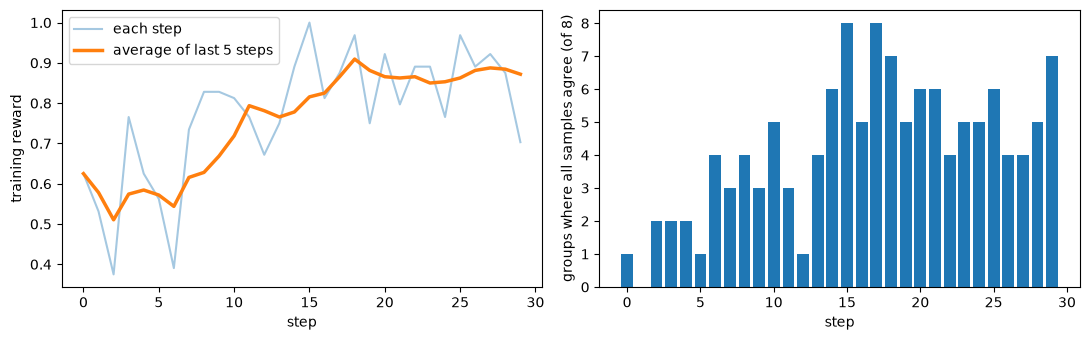

greedy accuracy on held-out problems: 0.765 before → 0.910 after 30 steps


In [59]:
history_table = pd.DataFrame(history)

fig, (reward_axis, same_axis) = plt.subplots(1, 2, figsize=(11, 3.5))

reward_axis.plot(history_table["reward"], alpha=0.4, label="each step")
reward_axis.plot(history_table["reward"].rolling(5, min_periods=1).mean(), linewidth=2.5, label="average of last 5 steps")
reward_axis.set_xlabel("step")
reward_axis.set_ylabel("training reward")
reward_axis.legend()

same_axis.bar(history_table.index, history_table["groups_all_same"])
same_axis.set_xlabel("step")
same_axis.set_ylabel(f"groups where all samples agree (of {QUESTIONS_PER_STEP})")

plt.tight_layout()
plt.show()

accuracy_after = evaluate(hf_generate_greedy)
print(f"greedy accuracy on held-out problems: {accuracy_before:.3f} before → {accuracy_after:.3f} after {NUM_STEPS} steps")

**The training reward goes up**, from around 0.55 to around 0.8, and the responses get shorter. Held-out accuracy is much noisier: across our runs it ended anywhere between 0.01 lower and 0.16 higher than it started. Thirty steps of 64 samples, one small optimizer step each, isn't much training, and 200 questions is a noisy measure (one question is half a percentage point). We'll get a clearer result once training is faster.

The right-hand plot shows a cost of that progress: as the model gets better, more groups are *all right*. Those groups have zero advantage and teach nothing, but they still cost a full share of generation. Towards the end, more than half of each step's samples are wasted that way. Real training runs deal with this by filtering out questions that are too easy, or by moving to harder ones (try `make_problems(..., hard=True)`).

### 1.7 More than one update per batch: the last ingredient of GRPO

Look at the timings: generating takes as long as updating, or longer. For bigger models and longer responses, generation dominates completely. And after all that work, we use each batch of samples for **one** optimizer step and throw it away.

Real trainers get more out of each batch: they split it into **mini-batches** and take one optimizer step per mini-batch. With 64 samples split into 2 mini-batches of 32, each batch gives 2 steps. Each sample is still trained on once; what gets reused is the expensive round of generation.

**The catch.** After the first mini-batch's step, the weights have changed. The second mini-batch's samples were generated by the *old* weights, and our loss has no idea how far the policy has already moved. Repeat that for several mini-batches (or several passes over the batch) and nothing stops one batch from pushing some tokens much further than one batch of evidence justifies.

PPO's fix, which GRPO uses too, keeps track of how far each token has moved since it was sampled, with the **ratio**:

$$\rho = \frac{\pi_\theta(\text{token})}{\pi_\text{old}(\text{token})}$$

where π_old is the token's probability when it was sampled (before any update), and π_θ is its probability now. ρ = 1 means "unchanged", 1.2 means "20% more likely than when it was sampled".

It then **clips** the objective: once a token has moved far enough in the direction its advantage wants (ρ above 1.28 for a good token, or below 0.8 for a bad one), its gradient becomes zero and the batch can't push it any further. If a token moved the *wrong* way, the gradient still flows, so the update can undo it.

Here's what that means for a single token that had probability 0.10 when it was sampled:

In [60]:
old_prob = 0.10           # π_old: the token's probability when it was sampled
clip_low, clip_high = 0.2, 0.28

for advantage in [+1.0, -1.0]:
    print(f"advantage A = {advantage:+.0f}")
    print(f"  {'new prob':>8}  {'ratio ρ':>7}  {'ρ·A':>6}  {'clip(ρ)·A':>9}  gradient")
    for new_prob in [0.05, 0.09, 0.10, 0.12, 0.15, 0.30]:
        ratio = new_prob / old_prob
        unclipped_objective = ratio * advantage
        clipped_objective = min(max(ratio, 1 - clip_low), 1 + clip_high) * advantage
        if clipped_objective < unclipped_objective:
            gradient = "zero: moved far enough, stop pushing"
        else:
            gradient = "flows"
        print(f"  {new_prob:8.2f}  {ratio:7.2f}  {unclipped_objective:+6.2f}  {clipped_objective:+9.2f}  {gradient}")
    print()

advantage A = +1
  new prob  ratio ρ     ρ·A  clip(ρ)·A  gradient
      0.05     0.50   +0.50      +0.80  flows
      0.09     0.90   +0.90      +0.90  flows
      0.10     1.00   +1.00      +1.00  flows
      0.12     1.20   +1.20      +1.20  flows
      0.15     1.50   +1.50      +1.28  zero: moved far enough, stop pushing
      0.30     3.00   +3.00      +1.28  zero: moved far enough, stop pushing

advantage A = -1
  new prob  ratio ρ     ρ·A  clip(ρ)·A  gradient
      0.05     0.50   -0.50      -0.80  zero: moved far enough, stop pushing
      0.09     0.90   -0.90      -0.90  flows
      0.10     1.00   -1.00      -1.00  flows
      0.12     1.20   -1.20      -1.20  flows
      0.15     1.50   -1.50      -1.28  flows
      0.30     3.00   -3.00      -1.28  flows



PPO takes the **smaller** (more pessimistic) of the two objectives, ρ·A and clip(ρ)·A. Reading the A = +1 table: while the token's probability rises from 0.10 towards 0.128 (ρ = 1.28), the plain ρ·A is the smaller one and the gradient keeps pushing it up. Beyond that (0.15, 0.30) the clipped value is smaller, and since it's a constant, the gradient is zero. If the token had moved the *wrong* way (0.05, 0.09), ρ·A is still the smaller one, so the gradient flows and can pull it back. The A = −1 table is the mirror image, with the limit at ρ = 0.8.

(The limits are asymmetric, 0.8 and 1.28 rather than 0.8 and 1.2: the "clip-higher" trick from DAPO, which leaves a bit more room to raise unlikely good tokens.)

As a loss (the negative of the objective), per token:

In [61]:
def clipped_token_losses(token_log_probs: torch.Tensor, old_token_log_probs: torch.Tensor, advantage: float,
                         clip_low: float = 0.2, clip_high: float = 0.28) -> torch.Tensor:
    """PPO's clipped loss for each token of one response."""
    ratio = torch.exp(token_log_probs - old_token_log_probs)  # π_θ / π_old, computed from log-probs
    unclipped_loss = -advantage * ratio
    clipped_loss = -advantage * ratio.clamp(1 - clip_low, 1 + clip_high)
    return torch.maximum(unclipped_loss, clipped_loss)  # the larger loss = the smaller (more pessimistic) objective

**On the first mini-batch, this is exactly our old loss.** Nothing has been updated yet, so π_θ = π_old and ρ = 1 for every token, well inside the clip range. The loss is −A × ρ, and π_old is a fixed number recorded before the update, so pushing ρ up means pushing π_θ up. It's even the same size of push as our old loss, −A × log π_θ: near ρ = 1, a small change in log π_θ changes ρ by the same small amount (ρ = e^(log π_θ − log π_old), and e^x ≈ 1 + x when x is small). So the first optimizer step is the same as before; the clipping only does something from the second mini-batch on.

The new step has one extra stage, between scoring and updating: record every token's log-prob **before** any update (π_old). Then for each mini-batch, accumulate the clipped loss over its samples and take one optimizer step. It also reports what the ratios looked like, so we can see the clipping at work.

In [ ]:
def rl_step_with_reuse(policy, optimizer, problems: list[dict], samples_per_prompt: int = 8, num_mini_batches: int = 2) -> dict:
    """Like rl_step_basic, but splits the batch into mini-batches: one optimizer step each, with PPO's clipped loss."""
    # 1-3. Sample, score and compute advantages: exactly as in rl_step_basic
    
    prompts = [chat_prompt_ids(problem["question"]) for problem in problems]
    samples = hf_generate(policy, prompts, samples_per_prompt)
    
    for sample_idx, sample in enumerate(samples):
        problem = problems[sample_idx // samples_per_prompt]
        sample["reward"] = reward_fn(decode_tokens(sample["response_ids"]), problem["answer"])
    
    for problem_idx in range(len(problems)):
        group = samples[problem_idx * samples_per_prompt : (problem_idx + 1) * samples_per_prompt]
        for sample, advantage in zip(group, grpo_group_advantages([sample["reward"] for sample in group])):
            sample["advantage"] = advantage

    # New: every token's log-prob under the weights that generated the samples (π_old), before any update
    for sample in samples:
        with torch.no_grad():
            sample["old_token_log_probs"] = response_token_log_probs(policy, sample["prompt_ids"], sample["response_ids"])

    # 4. Update: one optimizer step per mini-batch
    mini_batch_size = len(samples) // num_mini_batches
    mini_batch_stats = []
    
    for mini_batch_idx in range(num_mini_batches):
        mini_batch = samples[mini_batch_idx * mini_batch_size : (mini_batch_idx + 1) * mini_batch_size]
        num_response_tokens = sum(len(sample["response_ids"]) for sample in mini_batch)  # in this mini-batch

        all_ratios = []
        for sample in mini_batch:
            if sample["advantage"] == 0:
                continue

            token_log_probs = response_token_log_probs(policy, sample["prompt_ids"], sample["response_ids"])
            token_losses = clipped_token_losses(token_log_probs, sample["old_token_log_probs"], sample["advantage"])
            loss = token_losses.sum() / num_response_tokens
            loss.backward()
            
            all_ratios.append(torch.exp(token_log_probs - sample["old_token_log_probs"]).detach())

        torch.nn.utils.clip_grad_norm_(policy.parameters(), max_norm=1.0)
        optimizer.step()
        optimizer.zero_grad(set_to_none=True)

        if all_ratios:
            all_ratios = torch.cat(all_ratios)
            mini_batch_stats.append({
                "mini_batch": mini_batch_idx,
                "ratio_min": all_ratios.min().item(),
                "ratio_max": all_ratios.max().item(),
                "outside_clip_range": ((all_ratios < 0.8) | (all_ratios > 1.28)).float().mean().item(),
            })

    return {"reward": np.mean([sample["reward"] for sample in samples]), "mini_batches": mini_batch_stats}

Let's run the same experiment as before: start from the original model, use the same 30 batches of questions (the same `question_rng` seed), but take 2 optimizer steps per batch instead of 1. The generation cost is the same; only the updates double.

Each line also shows the ratios in the **second** mini-batch, where the policy has already moved since the samples were generated.

In [ ]:
policy.load_state_dict(original_weights)
optimizer = torch.optim.AdamW(policy.parameters(), lr=LR, weight_decay=0.01)
question_rng = random.Random(0)  # the same questions as the first run
history_with_reuse = []

for step in range(NUM_STEPS):
    problems = question_rng.sample(TRAIN, QUESTIONS_PER_STEP)
    metrics = rl_step_with_reuse(policy, optimizer, problems, samples_per_prompt=SAMPLES_PER_QUESTION, num_mini_batches=2)
    history_with_reuse.append(metrics)

    second_mini_batch = [stats for stats in metrics["mini_batches"] if stats["mini_batch"] == 1]
    
    if second_mini_batch:
        stats = second_mini_batch[0]
        ratio_summary = (f"2nd mini-batch: ratio {stats['ratio_min']:.2f} to {stats['ratio_max']:.2f}, "
                         f"{stats['outside_clip_range']:.2%} of tokens outside [0.8, 1.28]")
    else:
        ratio_summary = "2nd mini-batch: every group had zero advantage"
    print(f"step {step:2d} | reward {metrics['reward']:.3f} | {ratio_summary}")

accuracy_with_reuse = evaluate(hf_generate_greedy)

print(f"\ngreedy accuracy on held-out problems: {accuracy_before:.3f} before")
print(f"   after {NUM_STEPS} steps, 1 optimizer step per batch:  {accuracy_after:.3f}")
print(f"   after {NUM_STEPS} steps, 2 optimizer steps per batch: {accuracy_with_reuse:.3f}")

step  0 | reward 0.625 | 2nd mini-batch: ratio 0.73 to 1.28, 0.06% of tokens outside [0.8, 1.28]
step  1 | reward 0.531 | 2nd mini-batch: ratio 0.66 to 1.46, 0.32% of tokens outside [0.8, 1.28]
step  2 | reward 0.531 | 2nd mini-batch: ratio 0.56 to 1.42, 0.65% of tokens outside [0.8, 1.28]
step  3 | reward 0.812 | 2nd mini-batch: ratio 0.72 to 1.18, 0.21% of tokens outside [0.8, 1.28]
step  4 | reward 0.578 | 2nd mini-batch: ratio 0.63 to 1.42, 0.24% of tokens outside [0.8, 1.28]
step  5 | reward 0.688 | 2nd mini-batch: ratio 0.61 to 1.42, 0.37% of tokens outside [0.8, 1.28]
step  6 | reward 0.547 | 2nd mini-batch: ratio 0.74 to 1.44, 0.23% of tokens outside [0.8, 1.28]
step  7 | reward 0.828 | 2nd mini-batch: ratio 0.73 to 1.37, 0.22% of tokens outside [0.8, 1.28]
step  8 | reward 0.781 | 2nd mini-batch: ratio 0.65 to 1.21, 0.16% of tokens outside [0.8, 1.28]
step  9 | reward 0.953 | 2nd mini-batch: ratio 0.80 to 1.25, 0.09% of tokens outside [0.8, 1.28]
step 10 | reward 0.906 | 2nd m

The ratios show why we need π_old. In the second mini-batch they typically range from about 0.5 to 1.5, so the samples really are "out of date" by the time we train on them. (When every group in the first mini-batch had zero advantage, there was nothing to learn from it, the weights didn't change, and every ratio is exactly 1.) But only a small fraction of tokens, usually well under 1%, move outside [0.8, 1.28], so the clipping rarely kicks in. That's normal: with a small learning rate and only 2 mini-batches it's a **safety net**. It matters when a step moves the policy further: more mini-batches, several passes (*epochs*) over the same batch, a larger learning rate, or an unusual batch. Without it, every one of those extra steps would keep pushing the same tokens with the same force.

**Does it help?** One run of each can't tell us, whichever accuracy came out higher above. GPU arithmetic isn't bit-exact: a backward pass adds numbers up in an order that varies from run to run, so the weights after the first update differ in their last bits. Sooner or later, at some near-tie, a different token gets sampled, and from then on the run takes a different path. Two runs of this exact notebook, with the same code and the same seed, ended the 1-update run at 0.820 and at 0.925.

So we ran the comparison properly, outside the notebook: 3 seeds per setting, 60 steps of 16 questions × 8 samples, with greedy accuracy on 1,000 held-out questions every 10 steps. It uses the faster trainer we build in §2, so all 12 runs take about an hour rather than several hours. The script is `tools/reuse_experiment.py`, and its results are saved in the repo:

1 update per batch           accuracy at step 60: mean 0.929, seeds 0.921, 0.931, 0.934
2 updates per batch          accuracy at step 60: mean 0.870, seeds 0.876, 0.896, 0.839
4 updates per batch          accuracy at step 60: mean 0.841, seeds 0.865, 0.838, 0.819
4 updates, ¼ learning rate   accuracy at step 60: mean 0.942, seeds 0.946, 0.946, 0.934


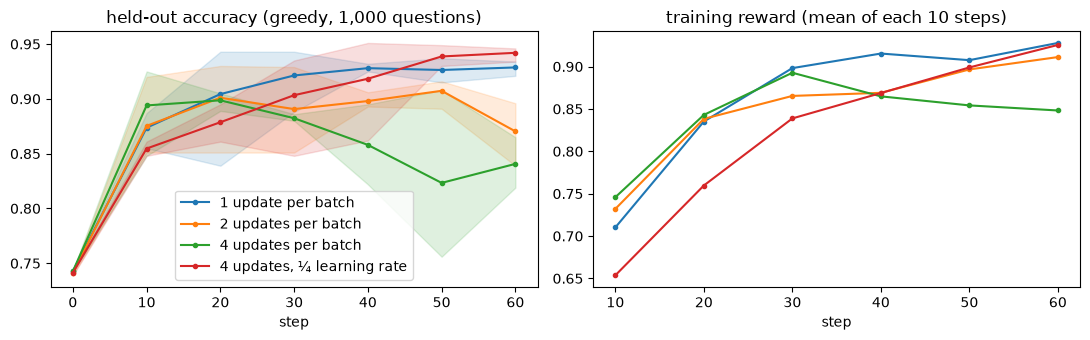

In [64]:
import json

reuse_runs = [json.loads(line) for line in open(REPO / "tutorial/series/results/reuse_experiment.jsonl")]
settings = {"1": "1 update per batch", "2": "2 updates per batch", "4": "4 updates per batch", "4_lr/4": "4 updates, ¼ learning rate"}

fig, (accuracy_axis, reward_axis) = plt.subplots(1, 2, figsize=(11, 3.5))
for setting, label in settings.items():
    runs = [run for run in reuse_runs if run["setting"] == setting]
    eval_steps = [int(step) for step in runs[0]["accuracy"]]
    accuracy = np.array([[run["accuracy"][str(step)] for step in eval_steps] for run in runs])  # (seeds, checkpoints)
    line, = accuracy_axis.plot(eval_steps, accuracy.mean(0), marker="o", ms=3, label=label)
    accuracy_axis.fill_between(eval_steps, accuracy.min(0), accuracy.max(0), color=line.get_color(), alpha=0.15)  # lowest to highest seed

    rewards = np.array([run["rewards"] for run in runs]).mean(0)  # mean over seeds, one value per step
    reward_axis.plot(range(10, len(rewards) + 1, 10), rewards.reshape(-1, 10).mean(1), marker="o", ms=3, label=label)  # mean of each 10 steps

    print(f"{label:28s} accuracy at step {eval_steps[-1]}: mean {accuracy[:, -1].mean():.3f}, "
          f"seeds {', '.join(f'{value:.3f}' for value in accuracy[:, -1])}")

accuracy_axis.set(title="held-out accuracy (greedy, 1,000 questions)", xlabel="step")
reward_axis.set(title="training reward (mean of each 10 steps)", xlabel="step")
accuracy_axis.legend()
plt.tight_layout()
plt.show()

Each line is the mean of 3 seeds; the shaded band runs from the lowest seed to the highest.

* **1 update per batch** is steady: every seed ends between 0.92 and 0.94.
* **More updates per batch, at the same learning rate**, start out level or slightly ahead, then fall back. With 4 updates, accuracy gets *worse* as training goes on, and the training reward drops with it, so it isn't an evaluation fluke.
* **4 updates at a quarter of the learning rate** learn more slowly at first, but don't fall back, and end slightly above 1 update.

So the problem is the size of each step, not the updates themselves. Adam moves each weight by roughly the learning rate per step, whatever the size of the gradient, so 4 steps per batch at the same learning rate move the policy about 4 times as far per batch. The clip limits how far a token can move *within* one batch; it can't stop the drift from adding up over many batches.

Taking several updates per batch is a trade: more learning from each round of generation, against training on samples a slightly older policy generated. It pays when generation is expensive (big models, long agent rollouts) and batches are large, and the number of mini-batches is tuned together with the learning rate. Here generation is cheap and the batches are small, so it barely matters. From here on we use 2 mini-batches per step anyway, as verl's recipes usually do: over the 20 steps of our later runs, 2 updates and 1 do equally well.

**This is GRPO in full:** group-relative advantages, and PPO's clipped ratio for taking several updates per batch. What's left is making it fast: training on many samples at once (§2), and, in notebook 2, a real inference engine for generating them.

## 2. Scaling up

### 2.1 Training on many samples at once

Look at the `update` times in the training runs above: several seconds per step, for 64 samples. Most of that is spent going through the samples **one at a time**: 64 separate forward passes and 64 separate backward passes, each on one short sequence. A GPU is built to do the same work on many rows at once, so one row at a time leaves most of it idle. We solved the same problem for generation by padding the prompts into one tensor; now we do it for training.

The difference is that a training row is a prompt **and** a response, and both have different lengths. Let's work with two real samples, one response each to two questions whose prompts have different lengths:

In [65]:
demo_prompts = [chat_prompt_ids(TRAIN[0]["question"]), chat_prompt_ids(TRAIN[3]["question"])]
demo_samples = hf_generate(policy, demo_prompts, samples_per_prompt=1)

for row, sample in enumerate(demo_samples):
    print(f"sample {row}: prompt {len(sample['prompt_ids'])} tokens, response {len(sample['response_ids'])} tokens")

sample 0: prompt 58 tokens, response 161 tokens
sample 1: prompt 57 tokens, response 176 tokens


**The layout: prompts are left-padded, responses right-padded.** With `P` = prompt token, `R` = response token, `·` = padding:

```
              prompts (left-padded)   responses (right-padded)
  sample 0:   ·   ·   P   P   P   │   R   R   R   R
  sample 1:   P   P   P   P   P   │   R   R   ·   ·
                                  ↑
                     every response starts in this column
```

Lining up the prompts' *ends*, as we did for generation, means every response starts in the same column (`prompt_width`). Later, one slice will then give us every row's response, instead of a different position for each row.

Let's build it for our two samples, together with the `attention_mask` (1 = real token, 0 = padding) that tells the model to ignore the padding:

In [66]:
prompt_width = max(len(sample["prompt_ids"]) for sample in demo_samples)        # the longest prompt
response_width = max(len(sample["response_ids"]) for sample in demo_samples)    # the longest response

demo_input_ids = torch.full((len(demo_samples), prompt_width + response_width), PAD_ID, dtype=torch.long)
demo_attention_mask = torch.zeros_like(demo_input_ids)

for row, sample in enumerate(demo_samples):
    prompt_start = prompt_width - len(sample["prompt_ids"])            # prompts are left-padded...
    response_end = prompt_width + len(sample["response_ids"])          # ...and responses right-padded
    demo_input_ids[row, prompt_start:prompt_width] = torch.tensor(sample["prompt_ids"])
    demo_input_ids[row, prompt_width:response_end] = torch.tensor(sample["response_ids"])
    demo_attention_mask[row, prompt_start:response_end] = 1


def as_blocks(mask_values) -> str:
    return "".join("█" if value else "·" for value in mask_values)


print("input_ids shape:", tuple(demo_input_ids.shape), f"= {prompt_width} prompt columns + {response_width} response columns\n")
for row, sample in enumerate(demo_samples):
    response_end = prompt_width + len(sample["response_ids"])
    print(f"sample {row}  start of the row: {as_blocks(demo_attention_mask[row, :4].tolist())}   "
          f"end of its response: {as_blocks(demo_attention_mask[row, response_end - 3 : response_end + 3].tolist())}")
print("\n█ = real token, · = padding")

input_ids shape: (2, 234) = 58 prompt columns + 176 response columns

sample 0  start of the row: ████   end of its response: ███···
sample 1  start of the row: ·███   end of its response: ███

█ = real token, · = padding


Sample 1's shorter prompt starts with one padding column, and the shorter response ends with padding on the right.

**Position IDs.** The model also needs to know each token's position in its sequence. By default it uses the column number, but in sample 1 the first real token sits in column 1, so the whole sample would be shifted by one position. The fix is to count the *real* tokens so far: a running sum of `attention_mask`, minus 1, gives 0, 1, 2, … from each row's first real token, whatever its padding. (The padding gets leftover values, but the attention mask hides it, so they never matter.)

In [67]:
demo_position_ids = (demo_attention_mask.cumsum(-1) - 1).clamp(min=0)

for row in range(len(demo_samples)):
    print(f"sample {row}  attention_mask {demo_attention_mask[row, :4].tolist()}  →  position_ids {demo_position_ids[row, :4].tolist()}")

sample 0  attention_mask [1, 1, 1, 1]  →  position_ids [0, 1, 2, 3]
sample 1  attention_mask [0, 1, 1, 1]  →  position_ids [0, 0, 1, 2]


Now **one forward pass for both samples**. The off-by-one is the same as in `response_token_log_probs`: the prediction for the token in column *t* comes from column *t − 1*. The response occupies columns `prompt_width` to the end, so the predictions for it come from columns `prompt_width - 1` up to the second-to-last: one slice, the same for every row.

In [68]:
with torch.no_grad(), torch.autocast("cuda", dtype=torch.bfloat16):
    demo_logits = policy(
        input_ids=demo_input_ids.to(DEVICE),
        attention_mask=demo_attention_mask.to(DEVICE),
        position_ids=demo_position_ids.to(DEVICE),
    ).logits
print("logits:", tuple(demo_logits.shape), "= (rows, columns, vocabulary)")

response_logits = demo_logits[:, prompt_width - 1 : -1].float()  # the columns that predict each response token
demo_log_probs_over_vocab = torch.log_softmax(response_logits, dim=-1)
demo_response_ids = demo_input_ids[:, prompt_width:].to(DEVICE)
print("log-probs of the response columns:", tuple(demo_log_probs_over_vocab.shape), "= (rows, response_width, vocabulary)")

logits: (2, 234, 151936) = (rows, columns, vocabulary)
log-probs of the response columns: (2, 176, 151936) = (rows, response_width, vocabulary)


For every row and every response column, we want one number from those 151,936: the log-prob of the token that's actually there. In `response_token_log_probs` that was a loop with `next_token_log_probs[token_id]`. **`gather`** does the same lookup for every row and column at once:

`token_log_probs[row, column] = log_probs_over_vocab[row, column, response_ids[row, column]]`

Let's check it against the loop, and against `response_token_log_probs`, which runs each sample on its own:

In [69]:
demo_token_log_probs = demo_log_probs_over_vocab.gather(-1, demo_response_ids.unsqueeze(-1)).squeeze(-1)  # (rows, response_width)

print("sample 0, first 5 response tokens: gather vs the loop lookup")
for column in range(5):
    token_id = demo_response_ids[0, column].item()
    looked_up = demo_log_probs_over_vocab[0, column, token_id].item()
    print(f"   {tokenizer.decode([token_id])!r:>10}  gather {demo_token_log_probs[0, column].item():.4f}   loop {looked_up:.4f}")

print("\nwhole responses: batched vs one sample at a time")
for row, sample in enumerate(demo_samples):
    with torch.no_grad():
        one_at_a_time = response_token_log_probs(policy, sample["prompt_ids"], sample["response_ids"])
    response_length = len(sample["response_ids"])
    batched = demo_token_log_probs[row, :response_length]  # the real tokens only
    print(f"   sample {row}: log π = {batched.sum().item():.3f} (batched) vs {one_at_a_time.sum().item():.3f} (one at a time), "
          f"largest per-token difference {(batched - one_at_a_time).abs().max().item():.4f}")

sample 0, first 5 response tokens: gather vs the loop lookup
         'To'  gather -0.0067   loop -0.0067
     ' solve'  gather -0.0003   loop -0.0003
       ' the'  gather -0.0000   loop -0.0000
   ' expression'  gather -0.0023   loop -0.0023
       ' \\('  gather -0.0011   loop -0.0011

whole responses: batched vs one sample at a time
   sample 0: log π = -3.134 (batched) vs -3.134 (one at a time), largest per-token difference 0.0000
   sample 1: log π = -8.375 (batched) vs -8.375 (one at a time), largest per-token difference 0.0000


In our run, sample 0 matched exactly. Sample 1, the row with padding, was close but not identical: log π differed by 0.4 over 207 tokens, and the largest single token by 0.18. That's not a bug. The model computes in bf16, which keeps only about 3 significant digits (a logit of 20 is stored to the nearest 0.125). A padded batch runs through different GPU kernels, which add things up in a different order, so the rounding comes out differently. Differences of this size are everywhere in RL training, and we'll meet them again between the trainer and vLLM (notebook 2, §2.6).

**The response mask.** We compared only each row's *real* response tokens. The padding columns get log-probs too, of whatever the model makes of a padding token, and they're meaningless:

In [70]:
demo_response_mask = demo_attention_mask[:, prompt_width:]  # 1 on real response tokens, 0 on padding

shorter_row = min(range(len(demo_samples)), key=lambda row: len(demo_samples[row]["response_ids"]))
response_length = len(demo_samples[shorter_row]["response_ids"])
columns = range(response_length - 2, response_length + 2)
print(f"sample {shorter_row}, around the end of its response:")
for column in columns:
    print(f"   column {column}: response_mask {demo_response_mask[shorter_row, column].item()}, log-prob {demo_token_log_probs[shorter_row, column].item():8.3f}")

sample 0, around the end of its response:
   column 159: response_mask 1, log-prob   -0.001
   column 160: response_mask 1, log-prob   -0.000
   column 161: response_mask 0, log-prob   -9.875
   column 162: response_mask 0, log-prob  -12.250


So the loss multiplies by a **response mask** (1 = train on this token, 0 = padding), and only counts the real tokens when it averages.

That's everything batching needs: padding, the attention mask, position IDs, one slice, `gather`, and the response mask. The functions the rest of the series uses wrap exactly these steps:

* **`make_padded_batch`** builds the padded tensors and masks, plus `prompts` and `responses` as separate blocks. It also takes an optional `response_masks`, for training on only *some* response tokens. We don't need that here, but notebook 3 does: in a conversation with tool calls, the tool's replies sit inside the response but weren't written by the model.
* **`micro_batch_log_probs`** is the forward pass, slice, `log_softmax` and `gather`. It adds one thing: `logits_to_keep=response_width + 1` asks the model for the scores at the last `response_width + 1` columns only. We never need the scores at the prompt columns, and every column costs 151,936 numbers. Keeping `response_width + 1` columns and dropping the last one is our `[prompt_width - 1 : -1]` slice.

In [71]:
def make_padded_batch(prompts: list[list[int]], responses: list[list[int]], response_masks: list[list[int]] | None = None) -> dict[str, torch.Tensor]:
    batch_size = len(prompts)
    prompt_width = max(len(prompt) for prompt in prompts)                       # the longest prompt
    response_width = max(1, max(len(response) for response in responses))     # the longest response (at least 1 column)

    prompt_ids = torch.full((batch_size, prompt_width), PAD_ID, dtype=torch.long)
    response_ids = torch.full((batch_size, response_width), PAD_ID, dtype=torch.long)
    attention_mask = torch.zeros((batch_size, prompt_width + response_width), dtype=torch.long)
    response_mask = torch.zeros((batch_size, response_width), dtype=torch.long)

    for row, (prompt, response) in enumerate(zip(prompts, responses)):
        prompt_start = prompt_width - len(prompt)  # prompts are left-padded...
        response_end = len(response)               # ...and responses right-padded
        prompt_ids[row, prompt_start:] = torch.tensor(prompt)
        response_ids[row, :response_end] = torch.tensor(response, dtype=torch.long)
        attention_mask[row, prompt_start : prompt_width + response_end] = 1
        trained = response_masks[row] if response_masks else [1] * len(response)  # default: train on every response token
        response_mask[row, :response_end] = torch.tensor(trained, dtype=torch.long)

    return {
        "prompts": prompt_ids,
        "responses": response_ids,
        "input_ids": torch.cat([prompt_ids, response_ids], dim=1),
        "attention_mask": attention_mask,
        # each token's position among the row's real tokens (0, 1, 2, ...), so left-padding doesn't shift positions
        "position_ids": (attention_mask.cumsum(-1) - 1).clamp(min=0),
        "response_mask": response_mask,
    }


def micro_batch_log_probs(model, micro_batch, with_grad: bool = False) -> torch.Tensor:
    """log π(token) for every response token; shape (rows, response_width)."""
    response_ids = micro_batch["responses"].to(DEVICE)
    response_width = response_ids.shape[1]

    with torch.set_grad_enabled(with_grad), torch.autocast("cuda", dtype=torch.bfloat16):
        logits = model(  # 1. one forward pass over prompt + response
            input_ids=micro_batch["input_ids"].to(DEVICE),
            attention_mask=micro_batch["attention_mask"].to(DEVICE),
            position_ids=micro_batch["position_ids"].to(DEVICE),
            logits_to_keep=response_width + 1,
        ).logits

    logits = logits[:, :-1].float()                # 2. position t-1 predicts token t, so drop the last position
    log_probs = torch.log_softmax(logits, dim=-1)  # 3. log-probs over the whole vocabulary
    token_log_prob = log_probs.gather(-1, response_ids.unsqueeze(-1)).squeeze(-1) # 4. the log-prob of the token actually there
    return token_log_prob


demo_batch = make_padded_batch([sample["prompt_ids"] for sample in demo_samples], [sample["response_ids"] for sample in demo_samples])
print("same masks as ours:", torch.equal(demo_batch["attention_mask"], demo_attention_mask), torch.equal(demo_batch["response_mask"], demo_response_mask))
difference = (micro_batch_log_probs(policy, demo_batch).cpu() - demo_token_log_probs.cpu()) * demo_response_mask
print("same log-probs as ours: largest difference", f"{difference.abs().max().item():.4f}")

same masks as ours: True True
same log-probs as ours: largest difference 0.0000


#### Is it faster?

Let's time a full training batch, 8 questions × 8 samples, both ways (log-probs only, without gradients):

In [72]:
timing_problems = TRAIN[:8]
timing_samples = hf_generate(policy, [chat_prompt_ids(problem["question"]) for problem in timing_problems], samples_per_prompt=8)
timing_batch = make_padded_batch([sample["prompt_ids"] for sample in timing_samples], [sample["response_ids"] for sample in timing_samples])
print("batch:", {name: tuple(tensor.shape) for name, tensor in timing_batch.items() if name in ("input_ids", "responses")})

torch.cuda.synchronize()
start_time = time.time()
with torch.no_grad():
    for sample in timing_samples:
        response_token_log_probs(policy, sample["prompt_ids"], sample["response_ids"])
torch.cuda.synchronize()
print(f"one at a time: {time.time() - start_time:.2f}s")

start_time = time.time()
with torch.no_grad():
    micro_batch_log_probs(policy, timing_batch)
torch.cuda.synchronize()
print(f"all at once:   {time.time() - start_time:.2f}s")

batch: {'responses': (64, 254), 'input_ids': (64, 312)}
one at a time: 1.39s
all at once:   0.11s


In our run: **1.38 s** one at a time, **0.11 s** all at once, about 12× faster for the same numbers. One short row leaves most of the GPU idle, and every pass pays the same fixed cost of launching each layer's work; a batch pays it once. Padding costs something back (every row is as long as the longest response), but much less than it saves.

#### Micro-batches

Speed isn't the only thing that changes when many rows go through the model together. Memory does too. For training we also need the **backward** pass, which needs the intermediate results ("activations") of every layer, for every token of every row, plus the logits: one row of 151,936 numbers for every response token, a copy after `log_softmax`, and the gradients of both. Let's measure the extra GPU memory a forward and backward pass takes, for the whole batch at once and for 8 rows at a time.

`select_rows` picks the same rows out of every tensor in a batch. (It also accepts verl's `TensorDict`, the batch container notebook 2 introduces.)

In [73]:
def select_rows(batch, index):
    """Index a batch given as a dict of tensors, or as verl's TensorDict (§3)."""
    if isinstance(batch, dict):
        return {key: tensor[index] for key, tensor in batch.items()}
    return batch[index]


def extra_memory_for_backward(rows) -> str:
    """Peak GPU memory a forward + backward pass over these rows adds, on top of what's already allocated."""
    micro_batch = select_rows(timing_batch, rows)
    torch.cuda.empty_cache()
    memory_before = torch.cuda.memory_allocated()
    torch.cuda.reset_peak_memory_stats()
    try:
        token_log_probs = micro_batch_log_probs(policy, micro_batch, with_grad=True)
        (token_log_probs * micro_batch["response_mask"].to(DEVICE)).sum().backward()
        extra = f"{(torch.cuda.max_memory_allocated() - memory_before) / 2**30:5.1f} GiB"
    except torch.OutOfMemoryError:
        extra = "out of memory"
    finally:
        policy.zero_grad(set_to_none=True)
        torch.cuda.empty_cache()
    return extra


print(f"all 64 rows at once: {extra_memory_for_backward(slice(0, 64))}")
print(f"8 rows at a time:    {extra_memory_for_backward(slice(0, 8))}")

all 64 rows at once:  58.6 GiB
8 rows at a time:      8.2 GiB


In our runs: **45 to 56 GiB** for all 64 rows at once (it depends on how long the responses are), against **6 to 8 GiB** for 8 rows. That's most of an 80 GB GPU, on top of the model and optimizer, and before we give part of the GPU to an inference engine (notebook 2, §2.3). Longer responses or a bigger model wouldn't fit at all.

So we go through a batch in **micro-batches**: a few rows at a time through the forward and backward pass. That's the **gradient accumulation** we already did in "One training step with advantages" (§1.5), one sample at a time: each `backward()` adds its gradients to the ones already there, and the optimizer steps once at the end. Now it's 8 samples at a time instead of 1.

`compute_log_probs` does it for the log-probs we only need to *read* (π_old), without gradients, 16 rows at a time:

In [74]:
def compute_log_probs(model, batch, micro_batch_size: int = 16) -> torch.Tensor:
    with torch.no_grad():
        model.eval()
        num_rows = batch["input_ids"].shape[0]
        chunks = []
        for start in range(0, num_rows, micro_batch_size):
            micro_batch = select_rows(batch, slice(start, start + micro_batch_size))
            chunks.append(micro_batch_log_probs(model, micro_batch))

    model.train()  # back to training mode, so ppo_update gets gradient checkpointing again
    return torch.cat(chunks).cpu()

This is the `load_policy` the rest of the series uses. It adds one line: **gradient checkpointing**, which saves memory by storing only some of the activations and recomputing the rest during the backward pass. Our short responses don't need it, but the long multi-turn conversations of notebook 3 do. It has one catch: in training mode it switches off the key/value cache that `generate` relies on, and `generate` then sees only the newest token at each step and writes word salad. That's why every generate function here calls `model.eval()` first, and `compute_log_probs` switches back to `model.train()` afterwards.

We'll load a fresh policy with it for the final training run. `make_optimizer` is a one-line helper for the optimizer we've been using.

In [75]:
def load_policy(path: str = MODEL):
    hf_logging.set_verbosity_error()  # also inside Ray workers
    model = AutoModelForCausalLM.from_pretrained(path, dtype=torch.float32, attn_implementation="flash_attention_2")  # fp32 master weights
    model = model.to(DEVICE)
    model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})  # recompute activations in backward: less memory
    model.config.use_cache = False  # the KV cache only speeds up generation, not training
    return model


def make_optimizer(model, lr: float):
    return torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)

#### The batched update

The update needs three more pieces, each a batched version of something we've already written.

**Advantages for a whole batch.** A batch now holds many groups. `grpo_advantages` replaces §1.5's `grpo_group_advantages`: it takes the rewards of the whole batch plus `group_ids`, which group (question) each sample belongs to, and applies exactly the formula from before to each group separately. Samples are prompt-major, so sample `i` belongs to group `i // samples_per_prompt`.

In [76]:
def grpo_advantages(rewards: torch.Tensor, group_ids, eps: float = 1e-6) -> torch.Tensor:
    """Each reward minus its group's mean, divided by its group's std. A group is all the attempts at one question."""

    advantages = torch.zeros_like(rewards)
    group_ids = np.asarray(group_ids)

    for group in np.unique(group_ids):
        members = torch.as_tensor(np.nonzero(group_ids == group)[0])  # row indices of this group's attempts
        group_rewards = rewards[members]

        if len(members) > 1:
            advantages[members] = (group_rewards - group_rewards.mean()) / (group_rewards.std() + eps)

    return advantages


# Our example groups from before, as one batch of 40 rewards
batch_rewards = torch.tensor([reward for group in example_groups.values() for reward in group], dtype=torch.float32)
batch_group_ids = [group_name for group_name, group in example_groups.items() for _ in group]
batch_advantages = grpo_advantages(batch_rewards, batch_group_ids)

for group_name, group_advantages in zip(example_groups, batch_advantages.split(10)):
    print(f"{group_name:24} {[round(advantage, 2) for advantage in group_advantages.tolist()]}")

mostly right (8 of 10)   [0.47, 0.47, -1.9, 0.47, -1.9, 0.47, 0.47, 0.47, 0.47, 0.47]
rarely right (1 of 10)   [-0.32, -0.32, -0.32, 2.85, -0.32, -0.32, -0.32, -0.32, -0.32, -0.32]
always right             [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
always wrong             [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]


The same advantages as before, group by group.

**The loss for a micro-batch.** `ppo_clip_loss` is `clipped_token_losses` on (rows, response_width) tensors, with each sample's advantage copied onto every one of its tokens. Two things are new:

* **`mask`** (the response mask) zeroes the loss on padding.
* **`num_trained_tokens`** is the number of trained tokens in the whole **mini-batch** (the rows of one optimizer step), not just in this micro-batch. That's what we did when we divided each sample's loss by `num_response_tokens` of the whole group: every micro-batch's `backward()` adds to the same gradients, so for the sum to be an average over the mini-batch, every micro-batch must divide by the same total.

Let's check it against `clipped_token_losses` on one real sample, at made-up ratios away from 1 so the clipping is active:

In [77]:
def ppo_clip_loss(log_probs, old_log_probs, advantages, mask, num_trained_tokens, clip_low: float = 0.2, clip_high: float = 0.28):
    ratio = torch.exp(log_probs - old_log_probs)  # ρ = π_θ / π_old, per token

    unclipped = -advantages * ratio

    clipped = -advantages * ratio.clamp(1 - clip_low, 1 + clip_high)

    loss = torch.maximum(unclipped, clipped)  # the larger loss = the smaller (more pessimistic) objective

    return (loss * mask).sum() / num_trained_tokens     # mean over trained tokens; num_trained_tokens counts the whole mini-batch (see ppo_update)


row = 0
num_tokens = len(timing_samples[row]["response_ids"])
old_token_log_probs = -torch.rand(num_tokens)                               # made-up π_old
new_token_log_probs = old_token_log_probs + 0.3 * torch.randn(num_tokens)   # made-up π_θ, far enough away to clip
advantage = 1.5

ours_per_sample = clipped_token_losses(new_token_log_probs, old_token_log_probs, advantage).sum() / num_tokens

# The same sample as one row of a padded batch
mask = timing_batch["response_mask"][row : row + 1].float()
padded_new = torch.zeros(mask.shape)
padded_new[0, :num_tokens] = new_token_log_probs
padded_old = torch.zeros(mask.shape)
padded_old[0, :num_tokens] = old_token_log_probs
batched = ppo_clip_loss(padded_new, padded_old, advantage * mask, mask, num_tokens)
print(f"clipped_token_losses: {ours_per_sample.item():.6f}   ppo_clip_loss: {batched.item():.6f}")

clipped_token_losses: -1.454410   ppo_clip_loss: -1.454410


**The update loop.** `ppo_update` is `rl_step_with_reuse`'s update loop, batched. It loops over the batch at two levels:

* **mini-batches**: the rows for one optimizer step, as in `rl_step_with_reuse`. With 128 rows and `mini_batch_size=64`, each batch gives 2 optimizer steps.
* **micro-batches**: the rows that go through the model together (8 here), with gradients accumulated over a mini-batch's micro-batches.

After each mini-batch: `clip_grad_norm_`, one optimizer step, and the gradients are reset, as before. The loss function is an argument, `loss_fn`, so that we can swap in another implementation: which is next.

In [78]:
def ppo_update(model, optimizer, batch, old_log_probs, advantages, mini_batch_size: int = 64, micro_batch_size: int = 8, loss_fn=ppo_clip_loss) -> dict:
    """One pass over the batch: one optimizer step per mini-batch, gradient accumulation over micro-batches."""
    num_rows = batch["input_ids"].shape[0]
    grad_norms = []
    for mini_start in range(0, num_rows, mini_batch_size):
        mini_end = min(mini_start + mini_batch_size, num_rows)
        num_trained_tokens = batch["response_mask"][mini_start:mini_end].sum().item()  # trained tokens in the whole mini-batch

        # Accumulate gradients over micro-batches small enough to fit in memory
        for micro_start in range(mini_start, mini_end, micro_batch_size):
            row_slice = slice(micro_start, min(micro_start + micro_batch_size, mini_end))
            micro_batch = select_rows(batch, row_slice)
            log_probs = micro_batch_log_probs(model, micro_batch, with_grad=True)
            mask = micro_batch["response_mask"].to(DEVICE).float()
            loss = loss_fn(log_probs, old_log_probs[row_slice].to(DEVICE), advantages[row_slice].to(DEVICE), mask, num_trained_tokens)
            loss.backward()

        # Then one optimizer step for the mini-batch
        grad_norms.append(torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0).item())
        optimizer.step()
        optimizer.zero_grad(set_to_none=True)
    return {"grad_norm": float(np.mean(grad_norms))}

### 2.2 Swapping in verl's algorithm functions

Every piece of maths in our trainer has a counterpart in [verl](https://github.com/volcengine/verl), the RL framework the rest of this series uses, and that real training runs use. `verl.trainer.ppo.core_algos` holds advantage estimators (GAE, GRPO, RLOO, REINFORCE++, …) and policy losses (vanilla PPO-clip, GSPO, CISPO, …), registered by name. They're the same ideas as ours, plus many variants and a lot of care for edge cases. From here on we use them, but only after checking, on our real batch, that they compute the same thing.

Swapping ours for theirs needs two adaptations.

**1. Rewards are per token.** verl expects `token_level_rewards`, with shape (rows, response_width): one reward per response token. A single score for a whole response goes on the response's **last real token**, with zeros everywhere else. Why per token? Some setups give different tokens different rewards: a penalty applied at every token, or a critic that spreads the final reward back over the tokens before it. GRPO only needs one number per response, so it simply sums each row, which gives back the original score. Here's that layout for the first two samples of our batch:

In [79]:
timing_rewards = torch.tensor([reward_fn(decode_tokens(sample["response_ids"]), timing_problems[i // 8]["answer"]) for i, sample in enumerate(timing_samples)])
mask = timing_batch["response_mask"]
lengths = mask.sum(-1)  # real tokens per row
token_level_rewards = torch.zeros(mask.shape)
token_level_rewards[torch.arange(len(lengths)), lengths - 1] = timing_rewards  # each reward on its row's last real token

for row in range(2):
    nonzero_columns = token_level_rewards[row].nonzero().flatten().tolist()
    print(f"row {row}: {lengths[row].item()} response tokens, reward {timing_rewards[row].item():.0f} → "
          f"token_level_rewards is nonzero at columns {nonzero_columns}, row sum {token_level_rewards[row].sum().item():.0f}")

row 0: 171 response tokens, reward 0 → token_level_rewards is nonzero at columns [], row sum 0
row 1: 155 response tokens, reward 0 → token_level_rewards is nonzero at columns [], row sum 0


(A row with reward 0 has no nonzero column at all: a reward of 0 on the last token is still 0.)

**2. The loss reads its settings from a config.** verl's vanilla policy loss takes its clip ratios from a config object, and the token count for averaging (`loss_agg_mode="token-mean"`) comes in through `config.global_batch_info`. That count is our `num_trained_tokens`: verl solved the same micro-batch accounting problem as `ppo_update`.

The cell below checks advantages, loss and log-probs. Advantages use random 0/1 rewards, so that more groups are mixed than in a real batch. For the log-probs, verl uses a fused kernel that computes the log-prob of the chosen token without building the full `log_softmax` table (the memory problem above).

In [80]:
from omegaconf import OmegaConf
from verl.trainer.ppo.core_algos import compute_grpo_outcome_advantage, get_policy_loss_fn
from verl.utils.torch_functional import logprobs_from_logits

# Advantages: ours vs verl's
group_size = 8
rewards = torch.tensor(np.random.default_rng(0).integers(0, 2, len(timing_samples)), dtype=torch.float32)
mask = timing_batch["response_mask"]
lengths = mask.sum(-1)
token_level_rewards = torch.zeros(mask.shape)
token_level_rewards[torch.arange(len(lengths)), lengths - 1] = rewards
uid = np.array([i // group_size for i in range(len(timing_samples))], dtype=object)  # group id per sample

our_advantages = grpo_advantages(rewards, uid)[:, None] * mask
verl_advantages, _ = compute_grpo_outcome_advantage(token_level_rewards=token_level_rewards, response_mask=mask, index=uid)
print("GRPO advantages match:", torch.allclose(our_advantages, verl_advantages, atol=1e-5))

# Loss: ours vs verl's vanilla PPO-clip, at ratios away from 1 so that clipping is active
verl_policy_loss = get_policy_loss_fn("vanilla")


def verl_ppo_loss(log_probs, old_log_probs, advantages, mask, num_trained_tokens, clip_low=0.2, clip_high=0.28, clip_c=3.0):
    config = OmegaConf.create({
        "clip_ratio": clip_low, "clip_ratio_low": clip_low, "clip_ratio_high": clip_high, "clip_ratio_c": clip_c,
        "global_batch_info": {"batch_num_tokens": num_trained_tokens, "dp_size": 1},
    })
    loss, _ = verl_policy_loss(old_log_prob=old_log_probs, log_prob=log_probs, advantages=advantages, response_mask=mask, loss_agg_mode="token-mean", config=config)
    return loss


old_log_probs = -torch.rand(mask.shape)
new_log_probs = old_log_probs + 0.5 * torch.randn(mask.shape)  # far enough from the old ones that clipping kicks in
loss_args = (new_log_probs, old_log_probs, verl_advantages, mask.float(), mask.sum().item())
print(f"PPO-clip loss: ours {ppo_clip_loss(*loss_args):.6f} | verl with dual-clip off {verl_ppo_loss(*loss_args, clip_c=1e9):.6f} "
      f"| verl with dual-clip (c=3) {verl_ppo_loss(*loss_args):.6f}")

# Log-probs: verl's fused kernel (flash-attn's cross-entropy) vs our log_softmax + gather
logits = torch.randn(4, 64, 5000, device=DEVICE)
labels = torch.randint(0, logits.shape[-1], logits.shape[:-1], device=DEVICE)
our_log_probs = torch.log_softmax(logits, -1).gather(-1, labels[..., None]).squeeze(-1)
print("log-probs match:", torch.allclose(our_log_probs, logprobs_from_logits(logits, labels), atol=1e-4))

2026-11-10 18:10:23,101	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


GRPO advantages match: True
PPO-clip loss: ours 0.091097 | verl with dual-clip off 0.091097 | verl with dual-clip (c=3) 0.088249
log-probs match: True


With dual-clip switched off, verl's loss is ours to the last digit. With it on (verl's default, `clip_ratio_c=3`), they differ slightly. **Dual-clip** fixes a gap in plain PPO-clip that the A = −1 table in the clipping section showed: when a token with a *negative* advantage has become much *more* likely (a large ratio), the loss −A·ρ keeps growing with the ratio, with no limit. A single token whose probability exploded could then dominate the whole update. Dual-clip caps that loss at c·|A|:

In [81]:
advantage = -1.0
clip_low, clip_high, clip_c = 0.2, 0.28, 3.0

print(f"{'ratio ρ':>8} {'PPO-clip loss':>14} {'with dual-clip':>15}")
for ratio in [0.5, 1.0, 2.0, 3.0, 5.0, 10.0]:
    clipped_ratio = min(max(ratio, 1 - clip_low), 1 + clip_high)
    ppo_loss = max(-advantage * ratio, -advantage * clipped_ratio)  # ppo_clip_loss, for one token
    dual_clip_loss = min(ppo_loss, -advantage * clip_c)             # verl: never more than c·|A| (negative A only)
    print(f"{ratio:8.1f} {ppo_loss:14.2f} {dual_clip_loss:15.2f}")

 ratio ρ  PPO-clip loss  with dual-clip
     0.5           0.80            0.80
     1.0           1.00            1.00
     2.0           2.00            2.00
     3.0           3.00            3.00
     5.0           5.00            3.00
    10.0          10.00            3.00


Up to ρ = 3 the two are identical; beyond it, dual-clip holds the loss at 3. The deliberately noisy ratios in the comparison above produce a few such tokens, which is the whole difference between the two numbers. In real training, with ratios near 1, they're rare.

#### The training step, batched

`rl_step` is the same loop as `rl_step_basic` in §1.6, **sample → score → advantages → update**, now built from the batched pieces, with verl's advantages and loss:

| | What happens | Result, for 8 questions × 8 samples |
|---|---|---|
| 1. sample | `generate` writes 8 samples for each of the 8 questions | 64 samples, prompt-major |
| | `group_ids = [i // 8 ...]` | `[0,0,0,0,0,0,0,0, 1,1,...,7]`: which question each sample answers |
| 2. score | `reward_fn` on each decoded response | `rewards`, shape (64,) |
| 3. batch | `make_padded_batch` | tensors with 64 rows |
| 4. old log-probs | `compute_log_probs` with the current weights | `old_log_probs`, shape (64, response_width): π_old |
| 5. advantages | rewards on each response's last token, then verl's `compute_grpo_outcome_advantage` | `advantages`, shape (64, response_width): each sample's advantage on all its tokens, 0 on padding |
| 6. update | `ppo_update` with `loss_fn=verl_ppo_loss` | one optimizer step per mini-batch |

Two more changes:

* `rl_step` takes the **generation function** as an argument (`generate`), just as `evaluate` does. That's what lets notebook 2 swap in a faster inference engine without touching anything else.
* The metrics include `format`, the fraction of responses with a `\boxed{}` number at all, right or wrong, which separates "learned the format" from "learned the arithmetic". And when the generation function reports its own log-probs for the tokens it sampled (`hf_generate` doesn't, and sets `"log_probs": None`; the inference engine in notebook 2 does), `logp_mismatch` compares them with ours. We'll look at that in the last section.

In [82]:
def rl_step(policy, optimizer, generate, problems, samples_per_prompt: int = 8, **update_kwargs) -> tuple[dict, dict, list[dict]]:
    timing = {}

    # 1. Sample several responses per problem (a GRPO group). Samples are prompt-major: sample i answers problem i // samples_per_prompt
    start = time.time()
    samples = generate([chat_prompt_ids(problem["question"]) for problem in problems], samples_per_prompt)
    timing["gen"] = time.time() - start
    group_ids = [i // samples_per_prompt for i in range(len(samples))]

    # 2. Score each response, and 3. pad everything into one batch
    texts = [decode_tokens(sample["response_ids"]) for sample in samples]
    rewards = torch.tensor([reward_fn(text, problems[group]["answer"]) for text, group in zip(texts, group_ids)])
    batch = make_padded_batch([sample["prompt_ids"] for sample in samples], [sample["response_ids"] for sample in samples])

    # 4. Log-probs under the weights that generated the samples (π_old)
    start = time.time()
    old_log_probs = compute_log_probs(policy, batch)
    timing["old_log_prob"] = time.time() - start

    # 5. Advantages with verl's GRPO estimator, which takes each response's reward on its last token
    last_token = batch["response_mask"].sum(-1).clamp(min=1) - 1
    token_level_rewards = torch.zeros(batch["response_mask"].shape)
    token_level_rewards[torch.arange(len(samples)), last_token] = rewards
    advantages, _ = compute_grpo_outcome_advantage(
        token_level_rewards=token_level_rewards, response_mask=batch["response_mask"], index=np.array(group_ids, dtype=object),
    )
    batch.update(old_log_probs=old_log_probs, advantages=advantages)  # kept for inspection after the update

    # 6. PPO update, with verl's loss
    start = time.time()
    stats = ppo_update(policy, optimizer, batch, old_log_probs, advantages, loss_fn=verl_ppo_loss, **update_kwargs)
    timing["update"] = time.time() - start

    metrics = {
        "reward": rewards.mean().item(),
        "format": float(np.mean([bool(BOXED.search(text)) for text in texts])),  # has a \boxed{integer} at all, right or wrong
        "response_len": batch["response_mask"].sum(-1).float().mean().item(),
        **stats,
    }
    if samples[0]["log_probs"] is not None:  # the inference engine returned its own log-probs: compare them with ours
        engine_log_probs = torch.zeros_like(old_log_probs)
        for row, sample in enumerate(samples):
            engine_log_probs[row, : len(sample["log_probs"])] = torch.tensor(sample["log_probs"])
        trained = batch["response_mask"].bool()
        metrics["logp_mismatch"] = (old_log_probs - engine_log_probs)[trained].abs().mean().item()
    metrics.update({f"time/{name}": seconds for name, seconds in timing.items()})
    return metrics, batch, samples


def print_step_metrics(step: int, metrics: dict) -> None:
    fmt = f" | format {metrics['format']:.2f}" if "format" in metrics else ""
    mismatch = f" | logp mismatch {metrics['logp_mismatch']:.4f}" if "logp_mismatch" in metrics else ""
    times = " ".join(f"{name.removeprefix('time/')} {seconds:4.1f}s" for name, seconds in metrics.items() if name.startswith("time/"))
    print(f"step {step:2d} | reward {metrics['reward']:.3f}{fmt} | len {metrics['response_len']:5.1f} | grad_norm {metrics['grad_norm']:.3f}{mismatch} | {times}")

A few steps with `hf_generate`, continuing from the model we have, to compare the timing with the one-sample-at-a-time loop:

In [83]:
for step in range(3):
    problems = question_rng.sample(TRAIN, QUESTIONS_PER_STEP)
    metrics, batch, samples = rl_step(policy, optimizer, lambda prompts, samples_per_prompt: hf_generate(policy, prompts, samples_per_prompt), problems)
    print_step_metrics(step, metrics)

step  0 | reward 0.922 | format 1.00 | len 135.9 | grad_norm 1.770 | gen  5.2s old_log_prob  0.1s update  0.6s
step  1 | reward 1.000 | format 1.00 | len 122.9 | grad_norm 0.000 | gen  5.9s old_log_prob  0.1s update  0.6s
step  2 | reward 0.828 | format 0.98 | len 149.6 | grad_norm 1.637 | gen  6.7s old_log_prob  0.1s update  0.6s


Compare the timings with the one-sample-at-a-time loop in §1.6: the update went from 4 to 6 s down to about **0.6 s**, and π_old takes 0.1 s. Generation is now almost all of each step: 4 to 7 s for 64 samples with `hf_generate`. That's the next thing to fix, and where notebook 2 starts.

## What we built

A complete GRPO trainer, one problem at a time:

| Problem | Solution | In code |
|---|---|---|
| How likely is a response? | sum the log-probs of its tokens, from one forward pass | `response_token_log_probs` → `micro_batch_log_probs` |
| Make good responses more likely | minimise −reward × log π (REINFORCE) | `loss.backward()`, `optimizer.step()` |
| Wrong answers are ignored; easy questions still get pushed | compare with the group: advantage = (reward − mean) / std | `grpo_advantages` |
| Generating one sample at a time is too slow | generate a whole batch at once, prompts left-padded | `hf_generate` |
| A real step uses many questions | one group per question, advantages within each group | `rl_step` |
| We throw samples away after one step | several mini-batch steps per batch, with PPO's clipped ratio | `ppo_clip_loss`, `ppo_update` |
| Our maths, in battle-tested code | verl's advantage and loss functions, checked against ours | `compute_grpo_outcome_advantage`, `verl_ppo_loss` |
| Training one sample at a time is slow | pad samples into one batch; micro-batches to fit in memory | `make_padded_batch`, `compute_log_probs` |

Every function that the rest of the series needs is also in `tutorial/lib/rl_core.py`, copied verbatim, so the next notebooks can import it instead of re-running this one.

**Next:** [notebook 2](2_from_trainer_to_verl.ipynb) fixes the slowest part of each step, generation, by handing it to a real inference engine (vLLM), then swaps the batch for verl's `DataProto` and splits this trainer into separate processes, the way verl runs it at scale, one swap at a time, until it *is* verl. First, free the GPU:

In [84]:
import gc

del policy, optimizer
gc.collect()
torch.cuda.empty_cache()
print(f"GPU free: {gpu_free_gib():.0f} GiB")

GPU free: 88 GiB


## Appendix: what did that step actually do?

In §1.5, "One training step with advantages" showed each response's log π moving up or down as a whole. But a response is a sequence of tokens, and the update doesn't treat them all the same. **Which tokens did it make more likely, and which less likely?** Our real responses are too long to follow by hand, so let's work through a small example: 10 responses to one question, where only one is correct.

First, its GRPO advantages:

In [85]:
# 10 responses to one question; only the first one is correct
example_rewards = torch.tensor([1.0] + [0.0] * 9)

mean_reward = example_rewards.mean()               # 1 right out of 10 = 0.1
reward_minus_mean = example_rewards - mean_reward  # +0.9 for the winner, -0.1 for each loser
std_reward = example_rewards.std()                 # sqrt((0.9**2 + 9 * 0.1**2) / 9): torch.std divides by n - 1 = 9, not 10
example_advantages = reward_minus_mean / std_reward

print(f"rewards: {example_rewards.tolist()}")
print(f"mean reward:        {mean_reward:.2f}")
print(f"reward - mean:      winner {reward_minus_mean[0]:+.2f}, each loser {reward_minus_mean[1]:+.2f}")
print(f"standard deviation: {std_reward:.3f}")
print(f"advantage:          winner {example_advantages[0]:+.3f}, each loser {example_advantages[1]:+.3f}")

rewards: [1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
mean reward:        0.10
reward - mean:      winner +0.90, each loser -0.10
standard deviation: 0.316
advantage:          winner +2.846, each loser -0.316


Our loss for the whole group adds up every sample's loss:

$$\text{loss} = -\sum_i A_i \log \pi(\text{response}_i)$$

so one gradient-descent step moves the weights θ in the direction

$$\Delta\theta \;\propto\; \underbrace{2.846\,\nabla \log \pi(\text{winner})}_{\text{one strong push up}} \;-\; \underbrace{0.316\,\big[\nabla \log \pi(\text{loser}_1) + \dots + \nabla \log \pi(\text{loser}_9)\big]}_{\text{nine weak pushes down}}$$

We can read ∇log π(response) as *the direction to change the weights so that this response becomes more likely*. Each response has its own direction, because each is made of different tokens. So the step says: move strongly in the winner's direction, and slightly away from each loser's. The advantages add up to zero, but because they multiply different gradients, only what the responses have in common cancels. 

To find out, recall from §1.3 that log π(response) is a sum of one term per token:

$$\log \pi(\text{response}) = \sum_t \log p(\text{token}_t \mid \text{the text before it}) = \log p(\text{token}_1) + \log p(\text{token}_2 \mid \text{token}_1) + \dots$$

Its gradient splits up the same way: each token's term has its own gradient, and they add up:

$$\nabla \log \pi(\text{response}) = \sum_t \nabla \log p(\text{token}_t \mid \text{the text before it})$$

The model predicts each token only from the text **before** it; it never sees what comes after. So each term depends on only two things: the text before it, and the token. 

If two responses contain the **same token after the same text**, that's literally the same term with the same gradient, and its weights add up. The same token after *different* text is a different term.

Let's consider a group of 10 responses to "What is 19 × 99 + 10?" and add up the weights, term by term. To keep it readable, we can split each response into a few chunks by hand, standing in for tokens.

In [86]:
# A hard question, "What is 19 × 99 + 10?", with 1 right answer out of 10.
# Each response is split into a few chunks by hand, standing in for tokens to keep it readable.
winner         = ["To solve this:", " 19 × 99 = 1881,", " plus 10 is 1891."]  # right: 1891
slip_a         = ["To solve this:", " 19 × 99 = 1881,", " plus 10 is 1901."]  # adds wrong
slip_b         = ["To solve this:", " 99 × 19 = 1881,", " plus 10 is 1901."]  # same slip, different wording before it
wrong_multiply = ["To solve this:", " 19 × 99 = 1871,", " plus 10 is 1881."]  # multiplies wrong

hard_group = [winner] + [slip_a] * 4 + [slip_b] * 3 + [wrong_multiply] * 2
hard_group_kinds = ["winner"] + ["slip_a"] * 4 + ["slip_b"] * 3 + ["wrong_multiply"] * 2  # which response is which
hard_group_rewards = [1] + [0] * 9
hard_group_advantages = grpo_group_advantages(hard_group_rewards)

# One row per response, with its chunks side by side so you can see where the responses diverge
hard_group_table = pd.DataFrame(hard_group, columns=["chunk 1", "chunk 2", "chunk 3"])
hard_group_table.insert(0, "kind", hard_group_kinds)
hard_group_table["reward"] = hard_group_rewards
hard_group_table["advantage"] = [round(advantage, 3) for advantage in hard_group_advantages]  # +2.846 for the winner, -0.316 for each loser
hard_group_table

,kind,chunk 1,chunk 2,chunk 3,reward,advantage
0,winner,To solve this:,"19 × 99 = 1881,",plus 10 is 1891.,1,2.846
1,slip_a,To solve this:,"19 × 99 = 1881,",plus 10 is 1901.,0,-0.316
2,slip_a,To solve this:,"19 × 99 = 1881,",plus 10 is 1901.,0,-0.316
3,slip_a,To solve this:,"19 × 99 = 1881,",plus 10 is 1901.,0,-0.316
4,slip_a,To solve this:,"19 × 99 = 1881,",plus 10 is 1901.,0,-0.316
5,slip_b,To solve this:,"99 × 19 = 1881,",plus 10 is 1901.,0,-0.316
6,slip_b,To solve this:,"99 × 19 = 1881,",plus 10 is 1901.,0,-0.316
7,slip_b,To solve this:,"99 × 19 = 1881,",plus 10 is 1901.,0,-0.316
8,wrong_multiply,To solve this:,"19 × 99 = 1871,",plus 10 is 1881.,0,-0.316
9,wrong_multiply,To solve this:,"19 × 99 = 1871,",plus 10 is 1881.,0,-0.316


Read down the chunk columns to see where the responses go their separate ways:

* **Chunk 1** is the same for all 10 responses.
* **Chunk 2** splits three ways: "19 × 99 = 1881," (the winner and the four `slip_a`), "99 × 19 = 1881," (the three `slip_b`) and "19 × 99 = 1871," (the two `wrong_multiply`).
* **Chunk 3**: only the winner wrote "plus 10 is 1891.".

Each response has a single advantage: +2.846 for the winner, −0.316 for every loser. Next, let's see what those response-level weights do to each chunk.

**Step 1: list every term.** Break each response into its terms: one per chunk, defined by the text before it and the chunk itself. (Every response starts from the same prompt, so we leave the prompt out of "text before".) 

The loss multiplies every term in a response by that response's advantage, so each term's **weight** is just its response's advantage: +2.846 for every term of the winner, −0.316 for every term of a loser.

In [87]:
# Step 1: every chunk of every response is one term. It gets its response's advantage as its weight.
term_rows = []
for response_idx, response in enumerate(hard_group):
    advantage = hard_group_advantages[response_idx]
    kind = hard_group_kinds[response_idx]

    for chunk_idx, chunk in enumerate(response):
        text_before = "".join(response[:chunk_idx])  # everything this response wrote before this chunk
        term_rows.append({"response": response_idx, "kind": kind, "text before": text_before, "chunk": chunk, "weight": advantage})

terms = pd.DataFrame(term_rows)
# Round only for display: the sums in step 2 use the full values, so the shared opening still cancels to exactly 0
terms.head(6).round(3)  # the winner's 3 terms, then the first loser's

,response,kind,text before,chunk,weight
0,0,winner,,To solve this:,2.846
1,0,winner,To solve this:,"19 × 99 = 1881,",2.846
2,0,winner,"To solve this: 19 × 99 = 1881,",plus 10 is 1891.,2.846
3,1,slip_a,,To solve this:,-0.316
4,1,slip_a,To solve this:,"19 × 99 = 1881,",-0.316
5,1,slip_a,"To solve this: 19 × 99 = 1881,",plus 10 is 1901.,-0.316


Compare the winner (rows 0 to 2) with the first loser (rows 3 to 5):

* **Rows 0 and 3** are the same chunk, "To solve this:", after the same (empty) text. So they're the **same term**, appearing once with +2.846 and once with −0.316.
* **Rows 1 and 4** are also the same term: both wrote " 19 × 99 = 1881," after "To solve this:".
* **Rows 2 and 5** are different terms: after the same text, the winner wrote "1891" and the loser "1901".

**Step 2: add up the weights of each term.** Across all 10 responses, group the rows that are the same term and add up their weights. 

**The key idea: a term's net weight is the sum of the advantages from the responses that contain it.** The `responses` column counts those responses, and the `calculation` column writes out the sum.

What does a net weight mean for the tokens? Each term is log p(chunk | text before it), so a **positive** net weight means the update makes that chunk **more likely** after that text, a **negative** one makes it **less likely**, and **0** leaves it unchanged. The bigger the weight, the bigger the change. The `effect` column spells this out.

In [88]:
# Step 2: the same chunk after the same text is the same term, so add up its weights
def weights_as_sum(weights: pd.Series) -> str:
    """Write out the sum, e.g. [2.846, -0.316, -0.316] -> '+2.846 + 2 × (-0.316)'. Weights are rounded to 3 decimals for display."""
    weight_counts = weights.round(3).value_counts(sort=False)  # each distinct weight, and how many times it appears
    parts = [f"{weight:+.3f}" if count == 1 else f"{count} × ({weight:+.3f})" for weight, count in weight_counts.items()]
    return " + ".join(parts)


net_weights = (
    terms.groupby(["text before", "chunk"], sort=False)
    .agg(responses=("response", "count"), calculation=("weight", weights_as_sum), net_weight=("weight", "sum"))
    .reset_index()
)
net_weights["net_weight"] = net_weights["net_weight"].round(2) + 0.0  # sums the full values; + 0.0 turns -0.0 into 0.0
net_weights["effect"] = net_weights["net_weight"].map(lambda weight: "more likely" if weight > 0 else "less likely" if weight < 0 else "unchanged")
net_weights

,text before,chunk,responses,calculation,net_weight,effect
0,,To solve this:,10,+2.846 + 9 × (-0.316),0.00,unchanged
1,To solve this:,"19 × 99 = 1881,",5,+2.846 + 4 × (-0.316),1.58,more likely
2,"To solve this: 19 × 99 = 1881,",plus 10 is 1891.,1,+2.846,2.85,more likely
3,"To solve this: 19 × 99 = 1881,",plus 10 is 1901.,4,4 × (-0.316),-1.26,less likely
4,To solve this:,"99 × 19 = 1881,",3,3 × (-0.316),-0.95,less likely
5,"To solve this: 99 × 19 = 1881,",plus 10 is 1901.,3,3 × (-0.316),-0.95,less likely
6,To solve this:,"19 × 99 = 1871,",2,2 × (-0.316),-0.63,less likely
7,"To solve this: 19 × 99 = 1871,",plus 10 is 1881.,2,2 × (-0.316),-0.63,less likely


In the step 2 table (`net_weights`), the `calculation` column shows where each net weight comes from: +2.846 if the winner contains that term, and −0.316 for each loser that does. Most rows follow directly from who wrote them (the summary below lists them all), but two are worth a closer look:

* **Row 4: a correct step becomes *less* likely.** "99 × 19 = 1881," is correct, but only losers wrote it that way, so its net weight is 3 × (−0.316) = −0.95. The reward is for the whole response, so a correct step inside wrong answers counts against it. Row 1, the same multiplication worded the way the winner wrote it, still comes out positive, but only +1.58: four losers each take 0.316 off the winner's +2.846.
* **Rows 3 and 5: the same slip shows up as two terms.** "plus 10 is 1901." appears after two different texts, so it's two different terms (−1.26 and −0.95). They're probably *similar* (the model's prediction depends mostly on the maths just before it), so together they make that slip less likely by roughly 2.2, more than any other mistake, because 7 losers made it. But that adds up only approximately, not exactly.

**So, which tokens does the update make more likely, and which less likely?** For this group, from most to least likely:

| effect | chunk | after | net weight | why |
|---|---|---|---|---|
| more likely | plus 10 is 1891. | To solve this: 19 × 99 = 1881, | +2.85 | only the winner wrote it |
| more likely | 19 × 99 = 1881, | To solve this: | +1.58 | the winner wrote it, but so did 4 losers |
| unchanged | To solve this: | *(start)* | 0 | all 10 responses wrote it |
| less likely | 19 × 99 = 1871, | To solve this: | −0.63 | 2 losers wrote it |
| less likely | plus 10 is 1881. | To solve this: 19 × 99 = 1871, | −0.63 | 2 losers wrote it |
| less likely | 99 × 19 = 1881, | To solve this: | −0.95 | only losers wrote it, **even though it's correct** |
| less likely | plus 10 is 1901. | To solve this: 99 × 19 = 1881, | −0.95 | 3 losers wrote it |
| less likely | plus 10 is 1901. | To solve this: 19 × 99 = 1881, | −1.26 | 4 losers wrote it |

The effect depends only on *who wrote each chunk*. This is how a reward for the whole response becomes credit for individual tokens, without anyone labelling which step was good.

Real responses diverge early and in many places, so far less is shared exactly, and making one token more likely also nudges others, through the shared weights. But the picture holds: **what all the responses share is left unchanged, what only the winner did becomes more likely, and mistakes become less likely in proportion to how common they are.**